# Swin Transformer from Scratch: Windows, Shifts, and a Hierarchy

> **Chapter 4 project (section 4.2):** Build a complete Swin Transformer in PyTorch, one function at a time, train it on CIFAR-10, and compare it with a plain ViT and with a Swin that never shifts its windows.

## Why this notebook matters

A ViT compares every token with every other token. With $N$ tokens that is $N^2$ comparisons per head, so halving the patch size multiplies the number of tokens by 4 and the attention cost by 16. That is why a plain ViT uses large patches and one coarse grid.

Swin makes three changes, and this notebook builds each one:

1. **Windows.** Attention runs only inside small square windows of tokens, so the cost grows with $N$, not $N^2$.
2. **Shifted windows.** Every second block moves the window boundaries, so information can cross from one window to the next.
3. **A hierarchy.** Patch merging joins 2 x 2 neighbors between stages: the grid gets coarser and the features get wider, as in a CNN.

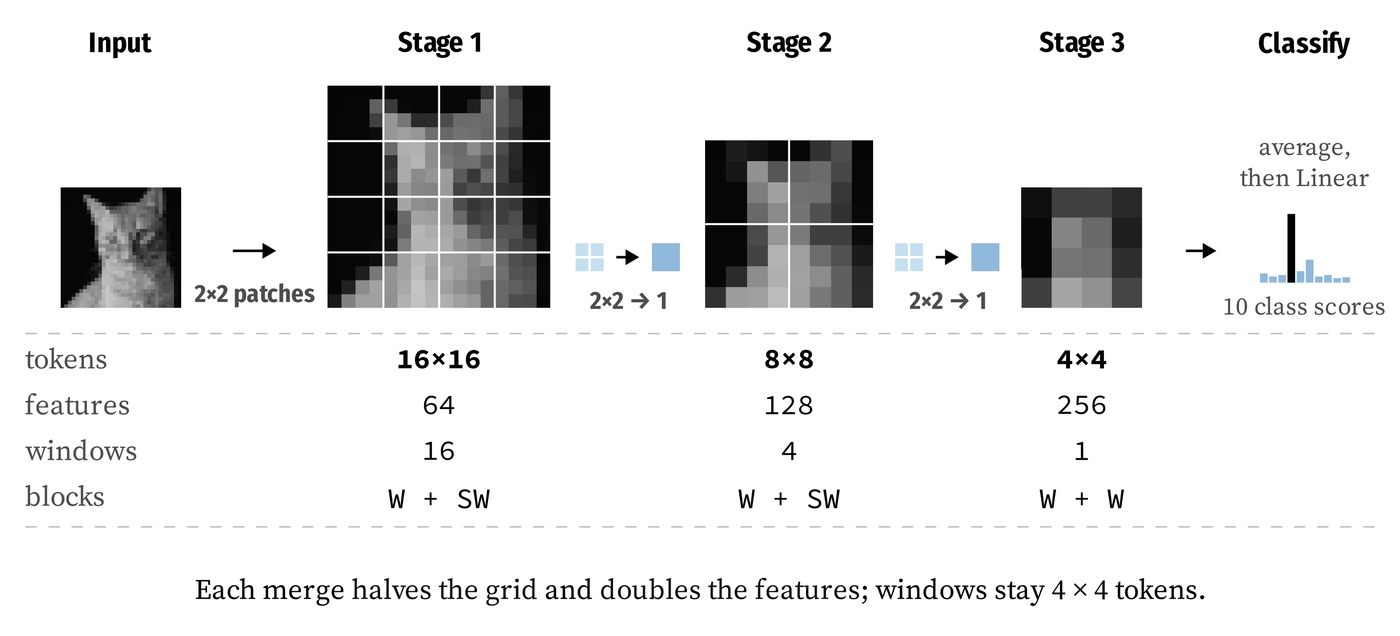

## What you will learn

By the end of this notebook you will be able to:

- partition a token grid into windows and put it back, and check both with a numbered grid;
- add a learned relative-position bias to window attention;
- build the shifted-window mask from region labels and see why it is needed;
- assemble Swin blocks, patch merging, and a three-stage classifier;
- **see** how far information travels with and without shifted windows;
- compare Swin with a plain ViT on accuracy, parameters, compute, and speed.

## The three models

| ID | Model | Attention | The question it answers |
| --- | --- | --- | --- |
| **W0** | ViT, 4 x 4 patches (64 tokens) | global, every block | The baseline from chapter 3 and the DeiT notebook |
| **W1** | Swin, 2 x 2 patches (256 tokens), 3 stages | 4 x 4 windows, shifted every second block | Does local attention plus a hierarchy help on a small dataset? |
| **W2** | W1 without the shift | 4 x 4 windows, never shifted | How much does the shift matter? |

All three use the same data, augmentation, schedule, and seed.

## Results at a glance

The saved outputs come from one full run on a T4 GPU (on Modal, 4 CPU cores). Your numbers will differ by a point or so.

| Model | Params | GMACs per image | Test top-1 | Images/s (T4) |
| --- | ---: | ---: | ---: | ---: |
| **W0 ViT, global attention** | 2.69M | 0.173 | **79.5%** | 5,783 |
| W1 Swin, shifted windows | 2.25M | 0.082 | 73.2% | 7,770 |
| W2 Swin, no shift | 2.25M | 0.082 | 72.5% | 7,773 |

- **Swin is cheaper.** It has 16% fewer parameters and less than half the GMACs, and it classifies 1.34x more images per second on a T4, even though its first stage works on a grid four times finer.
- **The plain ViT is more accurate here** (79.5% against 73.2%). On 32 x 32 images, global attention over 64 tokens is cheap, and our small Swin does half the ViT's work. Swin's advantages show with large images and dense tasks (see the limits in section 17).
- **The shift helps a little.** W1 beats W2 by 0.7 points with the same weights and cost. With one seed this gap is within noise; section 13 shows exactly what the shift changes.

## Roadmap

| Section | What you do | What you get |
| --- | --- | --- |
| 1-3 | Set up the device, settings, and data | CIFAR-10 split into train, validation, and test |
| 4 | Turn the image into a 16 x 16 token grid | Patch embedding for Swin |
| 5-6 | Partition into windows; count the attention cost | `window_partition`, `window_reverse` |
| 7-8 | Add relative positions and build window attention | `relative_index`, `WindowAttention` |
| 9 | Shift the windows and mask the wrapped pieces | `region_labels`, `mask_from_regions` |
| 10-12 | Build the block, patch merging, and the full model | `SwinBlock`, `PatchMerging`, `SwinCIFAR` |
| 13 | Watch information spread through the windows | Influence maps with and without the shift |
| 14-15 | Train and compare W0, W1, and W2 | Learning curves and a test-set table |
| 16 | Look inside the trained Swin | Learned position biases and window attention |
| 17 | Wrap up | Conclusions, limits, and experiments to try |

## Compute budget

| Hardware | Settings | Time |
| --- | --- | --- |
| T4 GPU (Modal, 4 CPU cores) | defaults | **measured:** about 18 minutes of training (about 6 per model), plus the one-time CIFAR-10 download (170 MB) |
| T4 GPU (free Colab) | defaults | estimate: 20-30 minutes; with only 2 CPU cores, preparing the augmented images can set the pace |
| CPU only | `TRAIN_SUBSET = 2000`, `EPOCHS = 2` | a few minutes, for following the workflow only |

> **TIP** Every finished model is saved to `./checkpoints`. If Colab disconnects, reconnect and choose **Runtime > Run all**. Finished models are loaded instead of retrained.

## Before you start

You should know the ViT from chapter 3 and have read section 4.2 of the chapter. The small numbered examples in sections 5, 7, and 9 are the same ones the chapter draws, so you can check each printed result against its figure. In Colab, choose **Runtime > Change runtime type > T4 GPU** before running anything.

## 1. Imports and device

In [1]:
#@title Imports
import os, time, math, json
from contextlib import nullcontext
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torch.utils.flop_counter import FlopCounterMode
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [2]:
#@title Device
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
print(device)

cuda


## 2. Hyperparameters

| Constant | Value | Meaning |
| --- | ---: | --- |
| `IMG_SIZE`, `PATCH_SIZE` | 32, 2 | Swin cuts the image into 2 x 2 patches: a **16 x 16 grid** of 256 tokens |
| `EMBED_DIM` | 64 | Features per token in stage 1; each merge doubles it (64, 128, 256) |
| `DEPTHS` | (2, 2, 2) | Blocks per stage: one regular and one shifted-window block |
| `HEADS` | (2, 4, 8) | Attention heads per stage; every head has 32 features, as in Swin-T |
| `WINDOW`, `SHIFT` | 4, 2 | 4 x 4 windows of 16 tokens; shifted blocks move the boundaries by half a window |
| `VIT_PATCH`, `VIT_DIM`, `VIT_DEPTH`, `VIT_HEADS` | 4, 192, 6, 3 | The W0 baseline: the same ViT as S0 in the DeiT notebook |
| `EPOCHS`, `LR`, `WEIGHT_DECAY`, `WARMUP_EPOCHS` | 30, 1e-3, 0.05, 3 | AdamW with a linear warmup and cosine decay, for all three models |
| `LABEL_SMOOTHING` | 0.1 | Softens the labels a little |
| `TRAIN_SUBSET` | `None` | Set to a number such as 2000 for a quick CPU run |

Real Swin-T uses 4 x 4 patches and 7 x 7 windows on 224 x 224 images, which gives a 56 x 56 grid. A 32 x 32 image is much smaller, so we use 2 x 2 patches and 4 x 4 windows. The structure is the same; only the sizes shrink.

**In pictures:** what the next cell does.

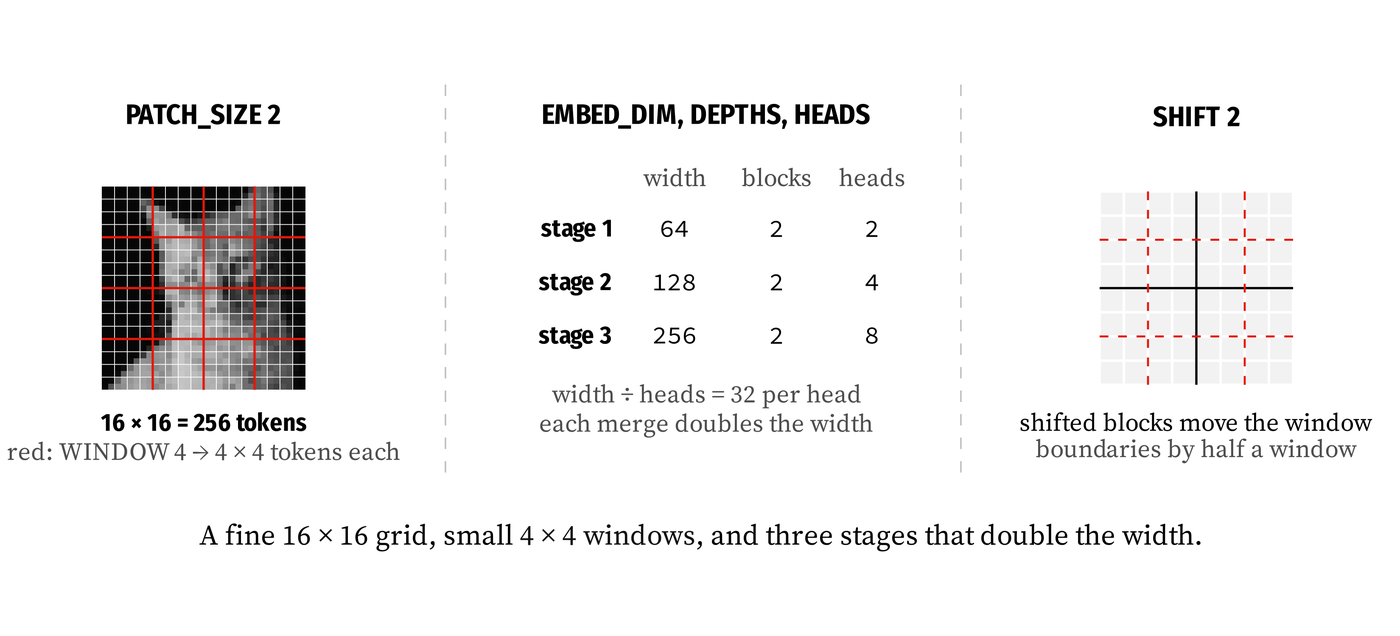

In [3]:
#@title Variables
DATA_DIR = './data'
CKPT_DIR = './checkpoints'
SEED = 42
IMG_SIZE = 32
CHANNELS = 3
CLASSES = 10
PATCH_SIZE = 2
GRID = IMG_SIZE // PATCH_SIZE
EMBED_DIM = 64
DEPTHS = (2, 2, 2)
HEADS = (2, 4, 8)
WINDOW = 4
SHIFT = 2
MLP_RATIO = 4
VIT_PATCH, VIT_DIM, VIT_DEPTH, VIT_HEADS = 4, 192, 6, 3
BATCH_SIZE = 128
EPOCHS = 30
LR = 1e-3
WEIGHT_DECAY = 0.05
WARMUP_EPOCHS = 3
LABEL_SMOOTHING = 0.1
TRAIN_SUBSET = None
NUM_WORKERS = min(4, os.cpu_count() or 1)
os.makedirs(CKPT_DIR, exist_ok=True)

## 3. Data: CIFAR-10 with train, validation, and test splits

We use the same split and augmentation as the DeiT notebook, so the ViT baseline W0 can be compared with S0 there.

```text
CIFAR-10 training set (50,000 images)
 |-- train        45,000   -> learn the weights (random crop, flip, TrivialAugment)
 |-- validation    5,000   -> pick the best epoch of each run
CIFAR-10 test set (10,000) -> final numbers, touched once at the end
```

**In pictures:** what the next cell does.

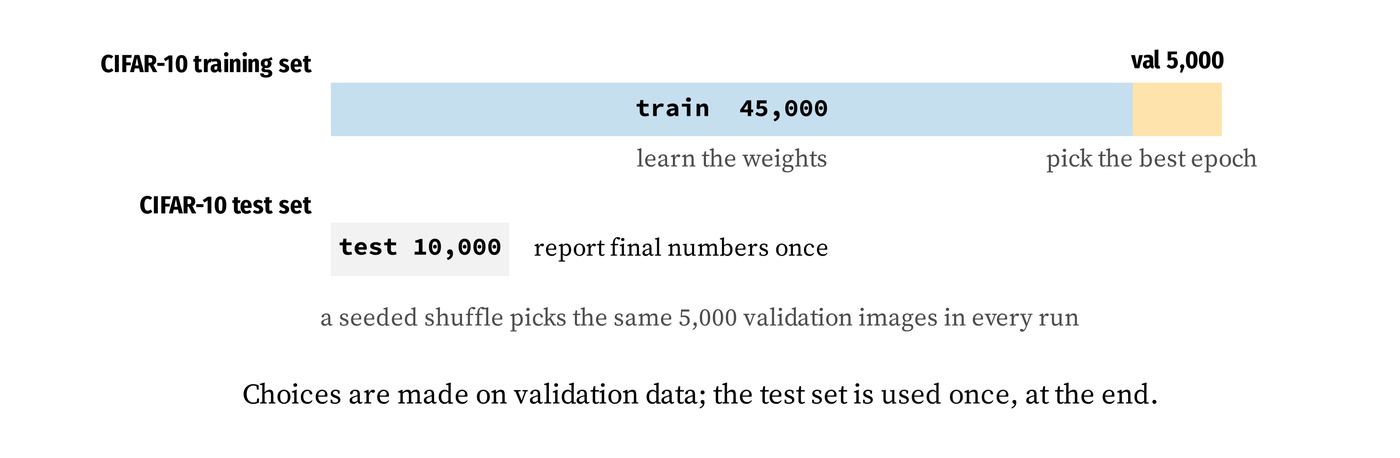
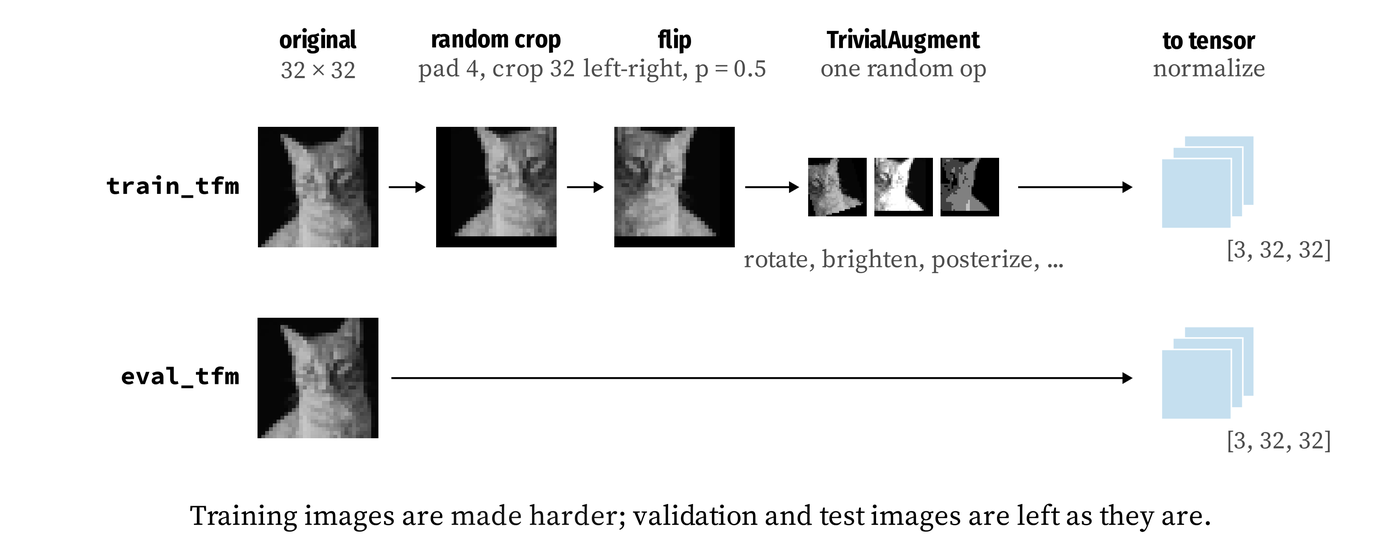

In [4]:
#@title Data
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
normalize = transforms.Normalize(MEAN, STD)
train_tfm = transforms.Compose([
    transforms.RandomCrop(IMG_SIZE, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(), normalize])
eval_tfm = transforms.Compose([transforms.ToTensor(), normalize])

train_set = datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=train_tfm)
val_set = datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=eval_tfm)
test_set = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=eval_tfm)
class_names = test_set.classes

order = torch.randperm(50_000, generator=torch.Generator().manual_seed(SEED)).tolist()
val_idx, train_idx = order[:5_000], order[5_000:]
if TRAIN_SUBSET:
    train_idx, val_idx = train_idx[:TRAIN_SUBSET], val_idx[:TRAIN_SUBSET // 4]

def make_loader(dataset, indices=None, train=False):
    data = Subset(dataset, indices) if indices is not None else dataset
    return DataLoader(data, batch_size=BATCH_SIZE, shuffle=train, drop_last=train,
                      num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0,
                      pin_memory=(device == 'cuda'))

train_dl = make_loader(train_set, train_idx, train=True)
val_dl = make_loader(val_set, val_idx)
test_dl = make_loader(test_set)
print(f'train {len(train_idx):,} | validation {len(val_idx):,} | test {len(test_set):,}')

def denorm(x):
    m, s = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
    return (x.cpu() * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

targets = np.array(val_set.targets)
cat_image = val_set[next(i for i in val_idx if targets[i] == class_names.index('cat'))][0]   # used in the pictures below

train 45,000 | validation 5,000 | test 10,000


## 4. Patch embedding: a 16 x 16 grid of tokens

Swin starts like a ViT: a convolution with kernel and stride equal to the patch size turns each patch into one token. The difference is the patch size. Our ViT baseline uses 4 x 4 patches and gets an 8 x 8 grid of 64 tokens. Swin uses 2 x 2 patches and gets a **16 x 16 grid of 256 tokens**, a four times finer view of the image.

For global attention, four times more tokens means sixteen times more query-key comparisons. Windows make the finer grid affordable. Unlike the ViT, Swin keeps track of the grid's height and width, because windows and merging need to know which tokens are neighbors.

The picture shows the 256 patches as thin lines and the 16 windows of 4 x 4 tokens as thick lines.

**In pictures:** what the next cell does.

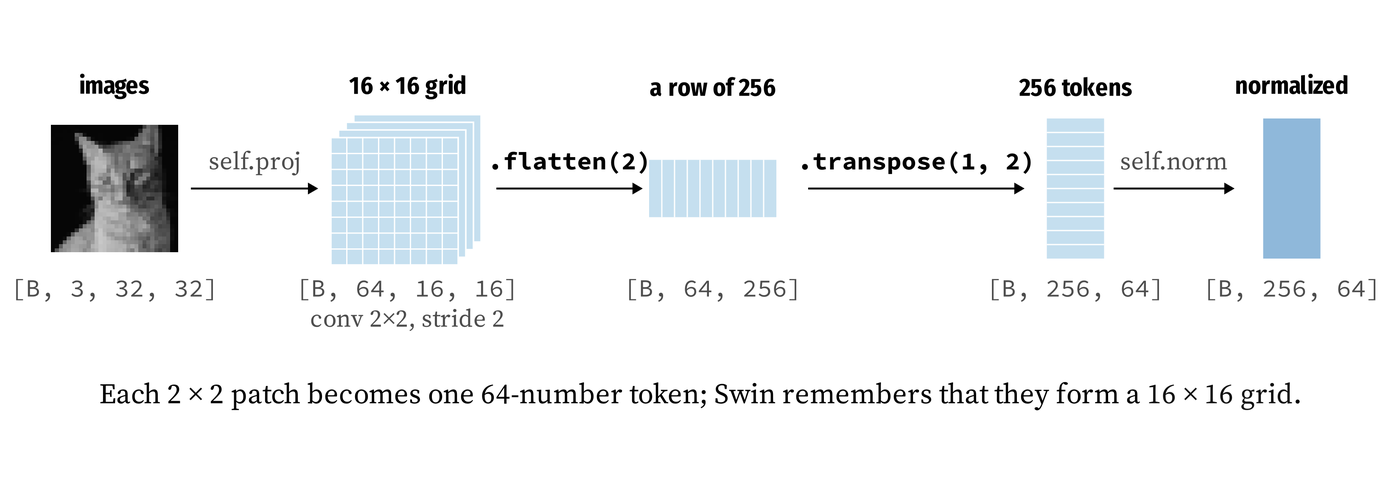

tokens: (2, 256, 64)  [batch, 16 x 16 tokens, features]


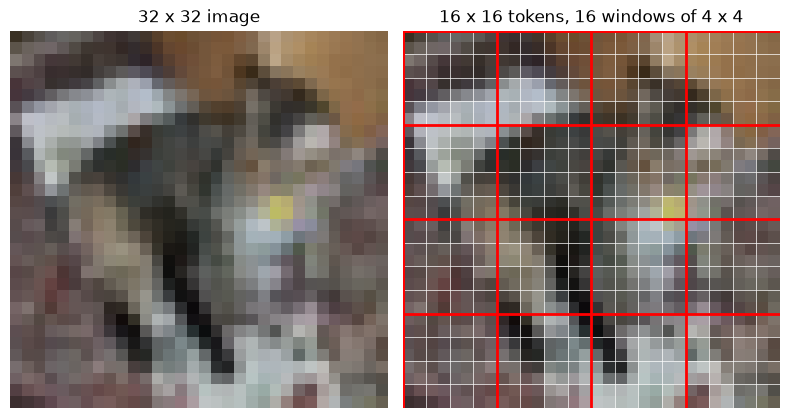

In [5]:
#@title Patch grid and windows on a real image
class PatchEmbed(nn.Module):
    def __init__(self, dim=EMBED_DIM, patch=PATCH_SIZE):
        super().__init__()
        self.proj = nn.Conv2d(CHANNELS, dim, patch, patch)
        self.norm = nn.LayerNorm(dim)
    def forward(self, images):
        grid = self.proj(images)                                           # [B, 64, 16, 16]
        tokens = grid.flatten(2).transpose(1, 2)                           # [B, 256, 64]
        return self.norm(tokens)

print('tokens:', tuple(PatchEmbed()(torch.randn(2, CHANNELS, IMG_SIZE, IMG_SIZE)).shape), ' [batch, 16 x 16 tokens, features]')

def draw_grid(ax, step, color, lw, offset=0):
    for k in range(0, IMG_SIZE + 1, step):
        p = (k + offset) % IMG_SIZE - 0.5
        ax.axhline(p, color=color, lw=lw); ax.axvline(p, color=color, lw=lw)

fig, axes = plt.subplots(1, 2, figsize=(8, 4.2))
axes[0].imshow(denorm(cat_image)); axes[0].set_title('32 x 32 image')
axes[1].imshow(denorm(cat_image)); draw_grid(axes[1], PATCH_SIZE, 'white', .5); draw_grid(axes[1], PATCH_SIZE * WINDOW, 'red', 2)
axes[1].set_title('16 x 16 tokens, 16 windows of 4 x 4')
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

## 5. Putting tokens into windows

Window attention needs each window's tokens side by side in memory, as one short sequence. `window_partition` does that with one reshape, one permute, and one more reshape. `window_reverse` undoes it. Both functions are the ones in listing 4.3 of the chapter.

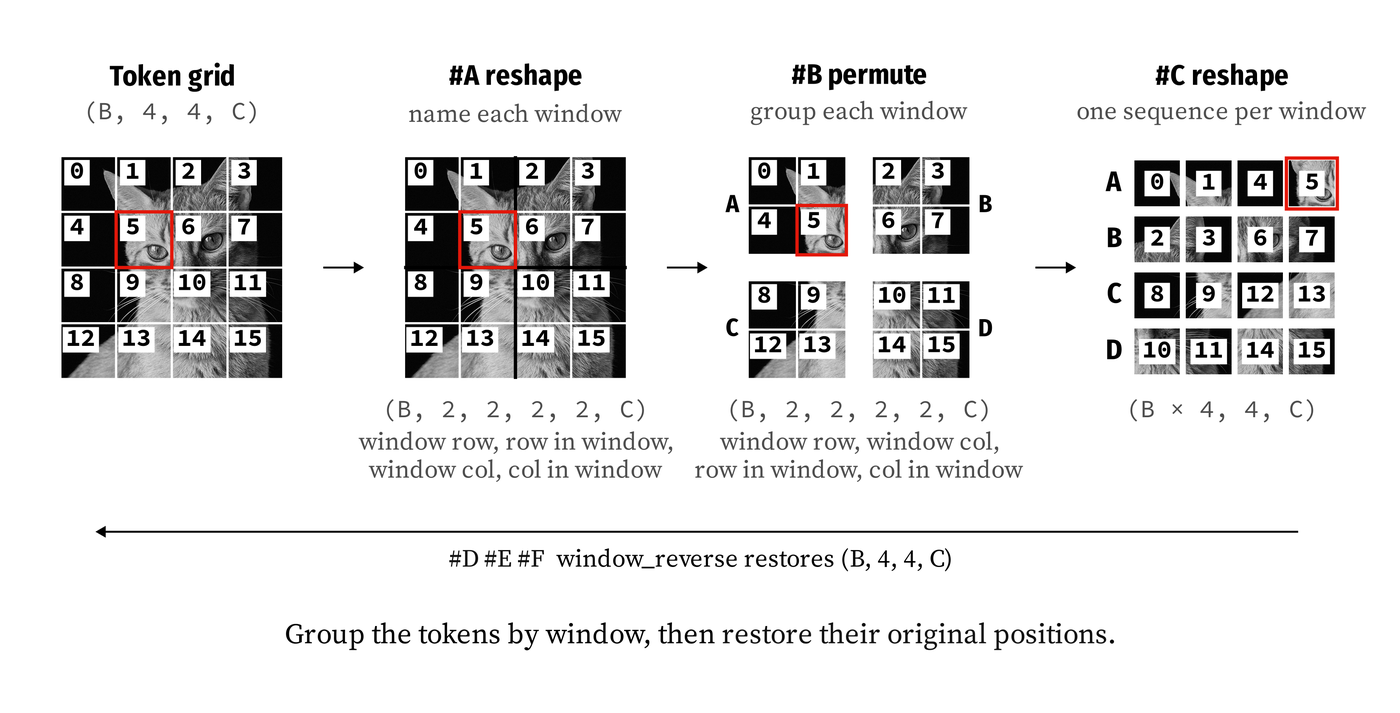

In [6]:
#@title window_partition and window_reverse
def window_partition(x, win):
    B, H, W, C = x.shape
    # Split both grid axes into a window index and a position within that window.
    x = x.reshape(B, H // win, win, W // win, win, C)
    # Group the window indices before the positions inside each window.
    x = x.permute(0, 1, 3, 2, 4, 5)
    # Put each window in the batch as a sequence of win * win tokens.
    return x.reshape(-1, win * win, C)

def window_reverse(windows, win, H, W):
    C = windows.shape[-1]
    # Restore the window-grid axes and the positions inside each window.
    x = windows.reshape(-1, H // win, W // win, win, win, C)
    # Interleave the window and within-window axes to recover image order.
    x = x.permute(0, 1, 3, 2, 4, 5)
    # Join those axes back into the original H by W grid.
    return x.reshape(-1, H, W, C)

Check it on the numbered grid from the chapter. The first window must hold tokens 0, 1, 4, and 5.

In [7]:
#@title Check on a numbered 4 x 4 grid
g = torch.arange(16).reshape(1, 4, 4, 1)
print(g[0, :, :, 0])
windows = window_partition(g, 2)
print(windows[:, :, 0])
print('restored exactly:', torch.equal(window_reverse(windows, 2, 4, 4), g))

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11],
        [12, 13, 14, 15]])
tensor([[ 0,  1,  4,  5],
        [ 2,  3,  6,  7],
        [ 8,  9, 12, 13],
        [10, 11, 14, 15]])
restored exactly: True


Now the real size. One 16 x 16 grid becomes **16 windows of 16 tokens**. Window attention will treat those 16 windows exactly like 16 separate short images in a batch. The picture shows the windows of our cat in batch order.

**In pictures:** what the next cell does.

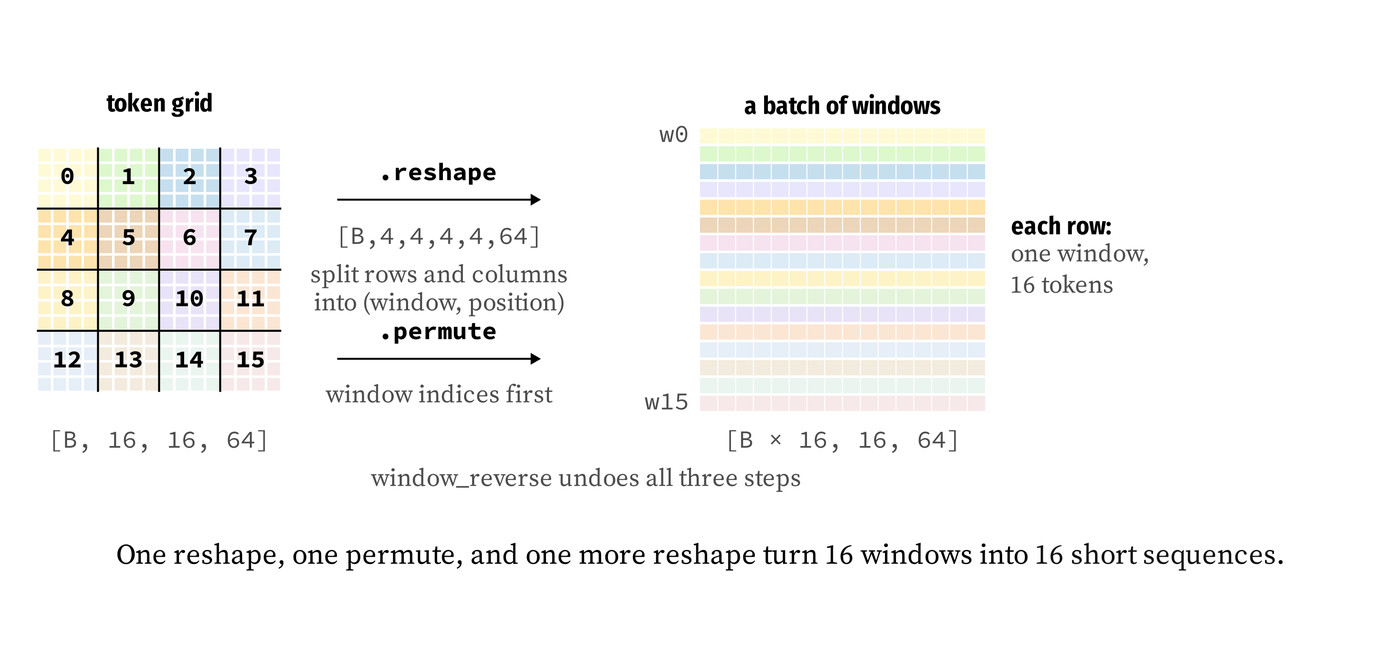

pixel windows: (16, 64, 3)
token windows: (32, 16, 64)  [2 images x 16 windows, 16 tokens, 64]


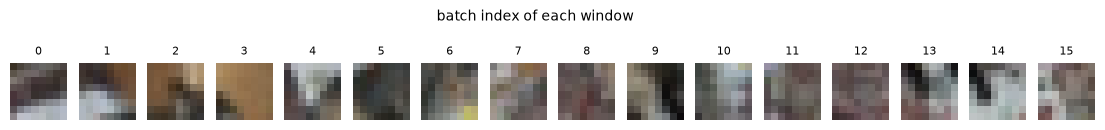

In [8]:
#@title The cat as a batch of 16 windows
pixels = cat_image.permute(1, 2, 0)[None]                                  # [1, 32, 32, 3], one pixel per position
win_px = PATCH_SIZE * WINDOW                                               # a window covers 8 x 8 pixels
pix_windows = window_partition(pixels, win_px)                             # [16, 64, 3]
print('pixel windows:', tuple(pix_windows.shape))
print('token windows:', tuple(window_partition(torch.zeros(2, GRID, GRID, EMBED_DIM), WINDOW).shape), ' [2 images x 16 windows, 16 tokens, 64]')
fig, axes = plt.subplots(1, 16, figsize=(14, 1.4))
for k, ax in enumerate(axes):
    ax.imshow(denorm(pix_windows[k].reshape(win_px, win_px, 3).permute(2, 0, 1))); ax.axis('off'); ax.set_title(f'{k}', fontsize=8)
plt.suptitle('batch index of each window', y=1.08, fontsize=10); plt.show()

## 6. What windows save

How many query-key scores does one attention layer compute per head? With global attention every token meets every token: $N^2$. With windows of $M \times M$ tokens, each token meets only the $M^2$ tokens of its window: $N \cdot M^2$.

**In pictures:** what the next cell does.

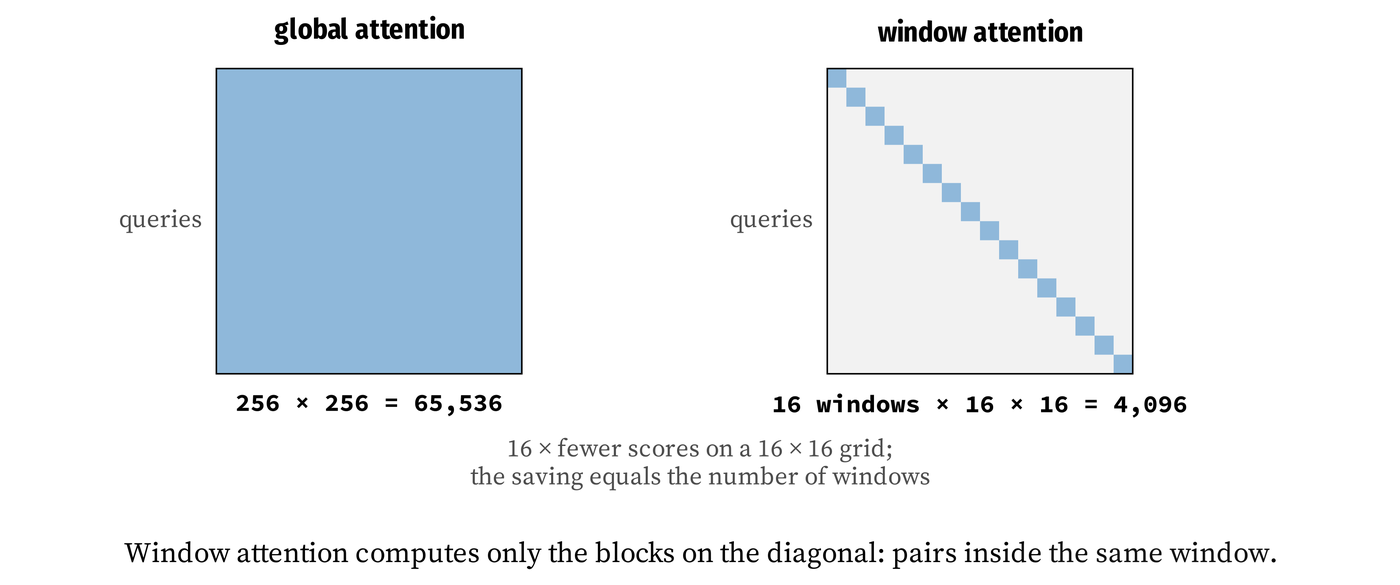

In [9]:
#@title Counting attention scores
def global_scores(grid):
    n = grid * grid
    return n * n

def window_scores(grid, win):
    return grid * grid * win * win

print(f'{"grid":>8s} {"tokens":>7s} {"global":>12s} {"windows":>10s} {"saving":>7s}')
for grid, win in [(8, 4), (16, 4), (32, 4), (56, 7)]:
    g_, w_ = global_scores(grid), window_scores(grid, win)
    print(f'{grid:>3d} x {grid:<3d} {grid * grid:7,d} {g_:12,d} {w_:10,d} {g_ / w_:6.0f}x   ({win} x {win} windows)')

    grid  tokens       global    windows  saving
  8 x 8        64        4,096      1,024      4x   (4 x 4 windows)
 16 x 16      256       65,536      4,096     16x   (4 x 4 windows)
 32 x 32    1,024    1,048,576     16,384     64x   (4 x 4 windows)
 56 x 56    3,136    9,834,496    153,664     64x   (7 x 7 windows)


The saving is the number of windows. Our 16 x 16 grid has 16 windows, so attention computes 16 times fewer scores than global attention would. Swin-T's first stage, 56 x 56 tokens with 7 x 7 windows, saves 64 times. More important than either number: doubling the image side multiplies the saving by four, because window attention grows with the number of tokens while global attention grows with its square.

## 7. Relative positions inside a window

Swin adds no absolute position embedding to the tokens. Instead, every attention score inside a window gets a learned **bias** that depends only on where the key sits relative to the query: one row up, two columns left, and so on. In a window of $M \times M$ tokens, the row offset runs from $-(M-1)$ to $M-1$, so a table of $(2M-1) \times (2M-1)$ numbers per head covers every pair. For our 4 x 4 windows that is a 7 x 7 table.

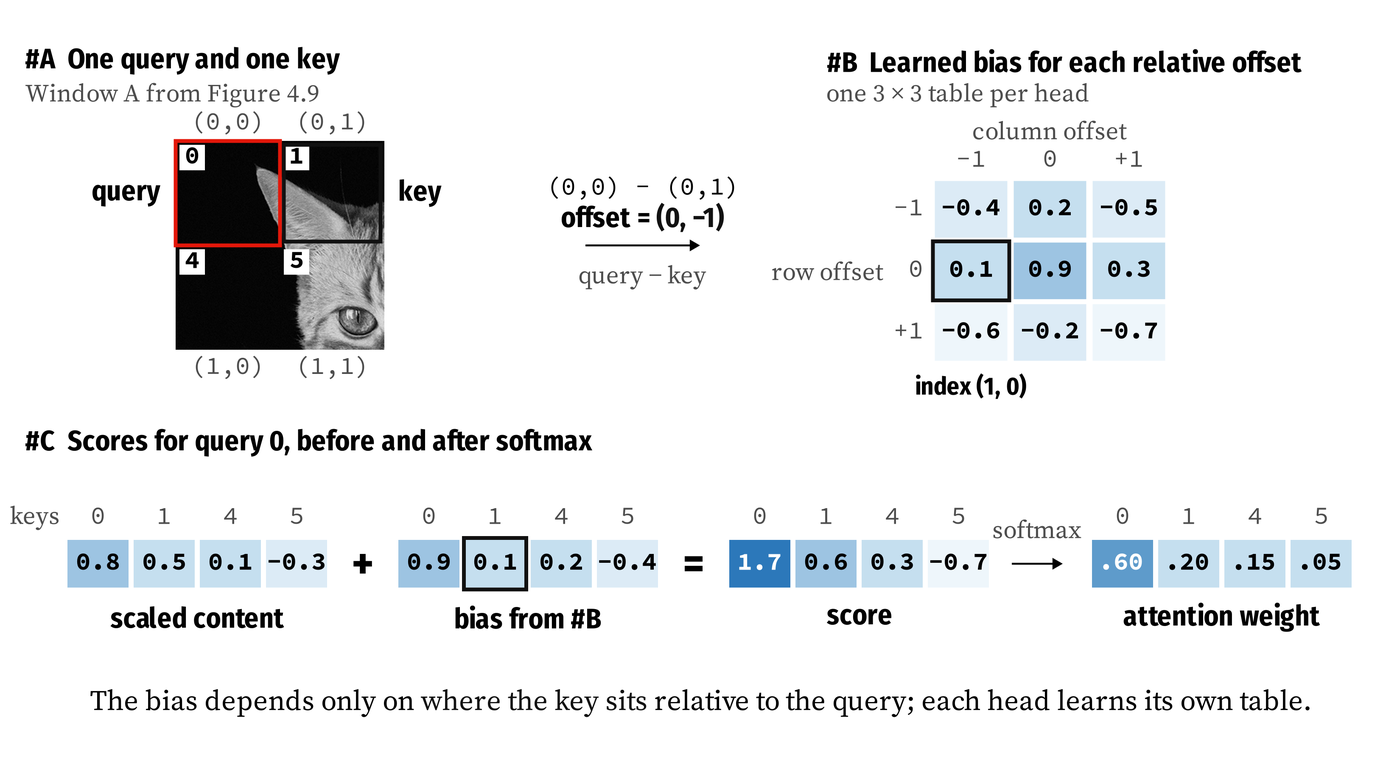

`relative_index` computes, for every (query, key) pair, the address of its entry in the table (listing 4.5).

**In pictures:** what the next cell does.

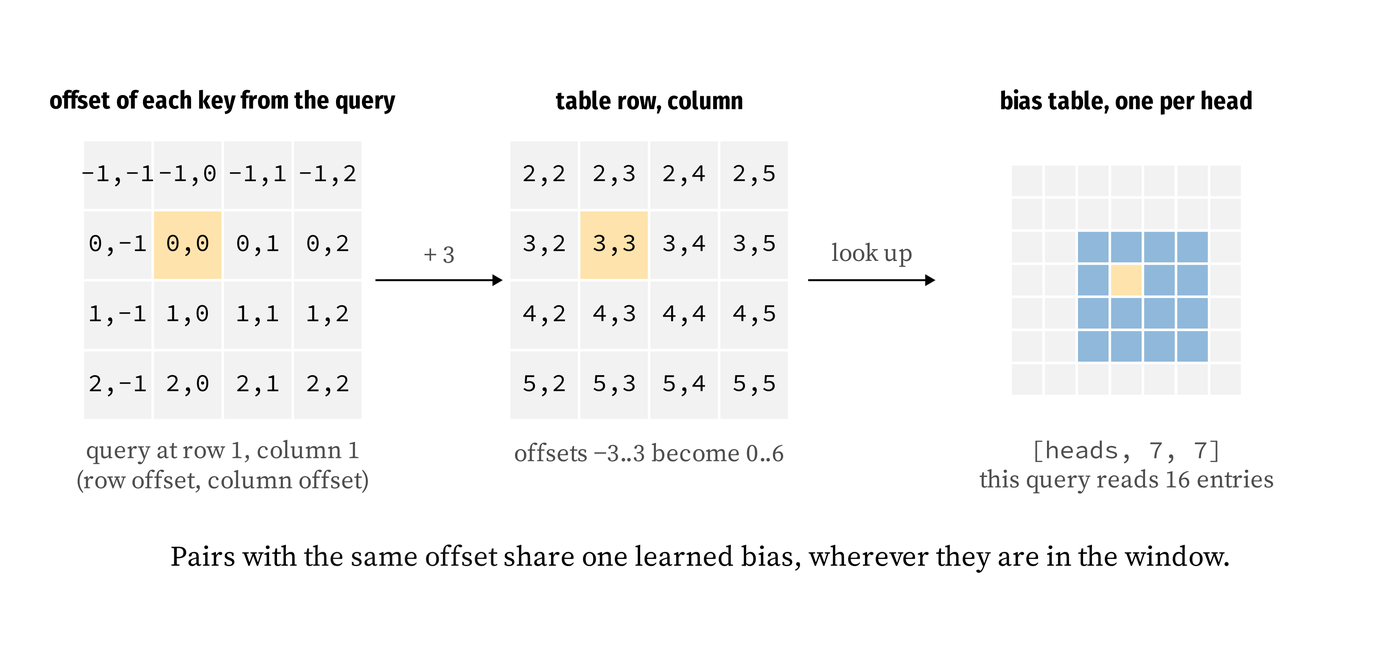

In [10]:
#@title relative_index
def relative_index(win):
    axis = torch.arange(win)
    rows, cols = torch.meshgrid(axis, axis, indexing='ij')
    # List each token's row and column coordinates: shape [2, win * win].
    coords = torch.stack([rows.flatten(), cols.flatten()])
    query_positions = coords[:, :, None]
    key_positions = coords[:, None, :]
    offsets = query_positions - key_positions
    # Shift signed offsets into table indices from 0 to 2 * win - 2.
    return offsets + win - 1

rel = relative_index(2)
print('2 x 2 window, table addresses (row * 3 + col):')
print(3 * rel[0] + rel[1])

2 x 2 window, table addresses (row * 3 + col):
tensor([[4, 3, 1, 0],
        [5, 4, 2, 1],
        [7, 6, 4, 3],
        [8, 7, 5, 4]])


These printed integers are addresses, not bias values. Every pair with the same offset shares one learned number. For our 4 x 4 windows the table has 49 entries, and the 16 x 16 matrix below shows which entry each query-key pair reads. The diagonal, offset (0, 0), always reads the middle of the table.

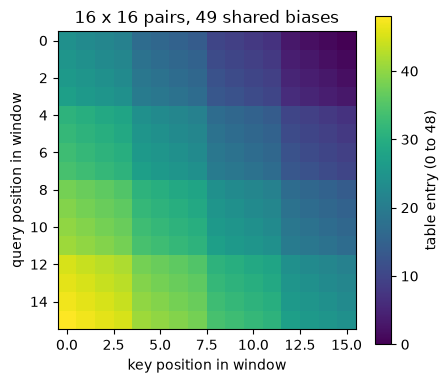

In [11]:
#@title Which table entry each pair reads, 4 x 4 window
rel4 = relative_index(WINDOW)
address = (2 * WINDOW - 1) * rel4[0] + rel4[1]
plt.figure(figsize=(4.6, 4))
plt.imshow(address, cmap='viridis'); plt.colorbar(label='table entry (0 to 48)')
plt.xlabel('key position in window'); plt.ylabel('query position in window')
plt.title('16 x 16 pairs, 49 shared biases'); plt.tight_layout(); plt.show()

## 8. Window attention

Window attention is ordinary multi-head attention applied to the batch of windows, plus two additions before the softmax: the relative-position bias, and, in shifted blocks, a mask. `window_weights` adds both (listing 4.7). The mask holds one 16 x 16 matrix per window, so the scores are briefly reshaped to line windows up with their masks.

**In pictures:** what the next cell does.

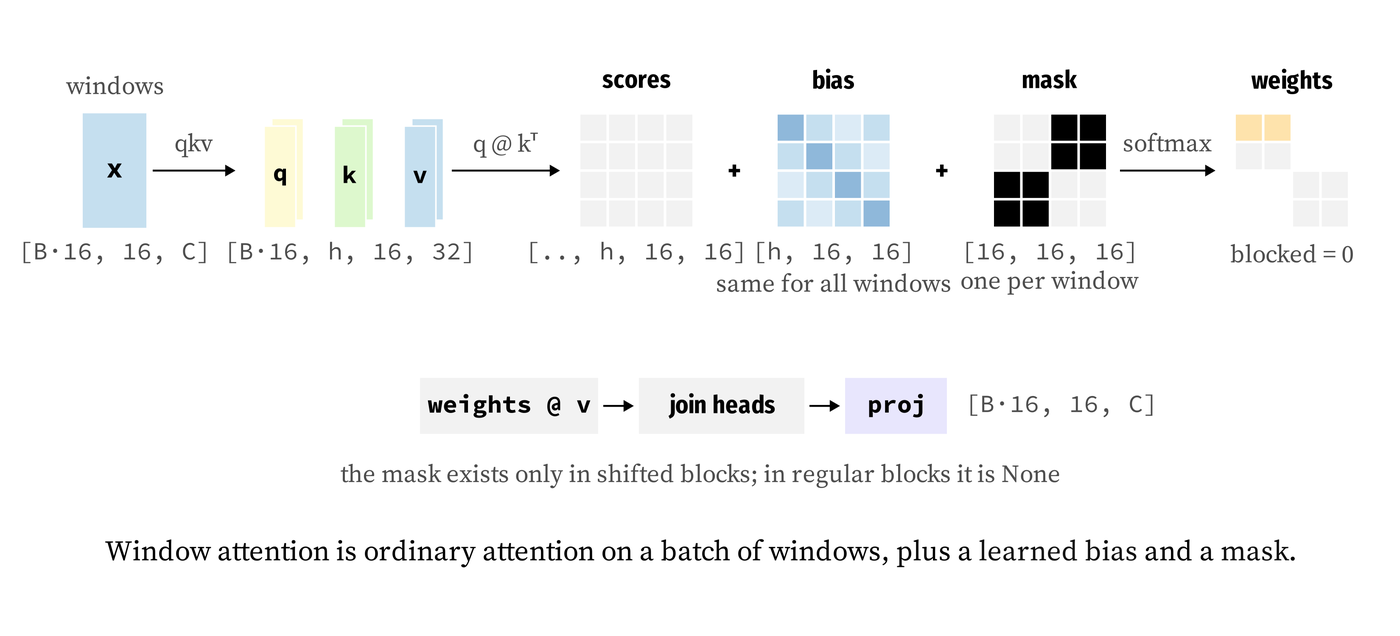

In [12]:
#@title window_weights and WindowAttention
def window_weights(scores, bias, mask=None):
    # Add the same per-head relative-position bias to every window.
    scores = scores + bias.to(scores)
    if mask is not None:
        BW, heads, N, _ = scores.shape
        window_count = mask.shape[0]
        # Separate images and windows so each window receives its own mask.
        scores = scores.reshape(-1, window_count, heads, N, N)
        # Add negative infinity to blocked pairs so softmax gives them zero weight.
        scores = scores + mask[None, :, None].to(scores)
        scores = scores.reshape(BW, heads, N, N)
    return scores.softmax(dim=-1)

class WindowAttention(nn.Module):
    def __init__(self, dim, heads, win):
        super().__init__()
        self.heads = heads
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)
        self.register_buffer('rel', relative_index(win))
        # Learn a separate table of relative-position biases for each head.
        self.table = nn.Parameter(torch.zeros(heads, 2 * win - 1, 2 * win - 1))
        nn.init.trunc_normal_(self.table, std=0.02)
        self.keep_weights, self.weights = False, None
    def forward(self, x, mask=None):
        BW, N, C = x.shape
        qkv = self.qkv(x).reshape(BW, N, 3, self.heads, -1)
        q, k, v = qkv.permute(2, 0, 3, 1, 4)
        scores = (q @ k.transpose(-2, -1)) * q.shape[-1] ** -0.5
        # Look up the bias for every query-key offset in the window.
        bias = self.table[:, self.rel[0], self.rel[1]]
        weights = window_weights(scores, bias, mask)
        if self.keep_weights:
            self.weights = weights.detach()
        mixed = (weights @ v).transpose(1, 2).reshape(BW, N, C)
        return self.proj(mixed)

## 9. Shifted windows and the mask

With fixed windows, a token can never exchange information with the token just across a window boundary. Swin fixes this by moving the boundaries in every second block. It does not move the windows; it **rolls the token grid** up and left by `SHIFT` positions with `torch.roll`, and then partitions as usual.

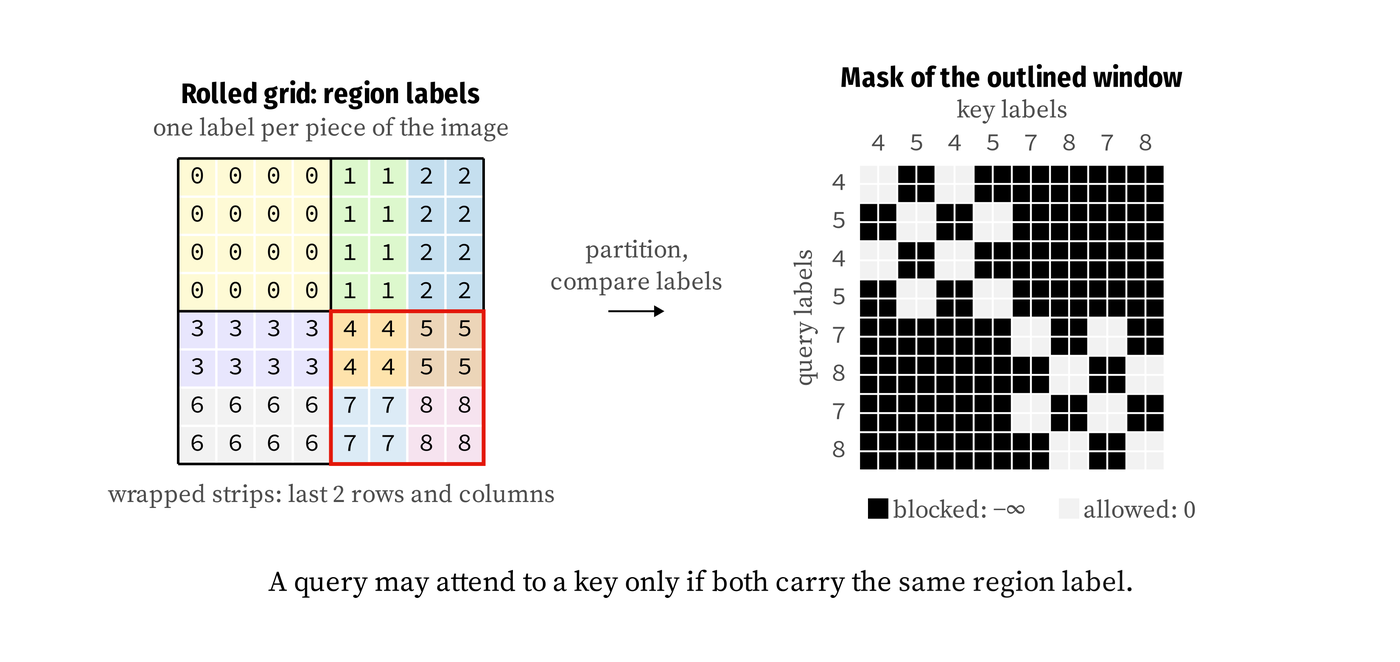

Rolling the chapter's numbered grid by one position brings the interior group 5, 6, 9, and 10 into the top-left window:

**In pictures:** what the next cell does.

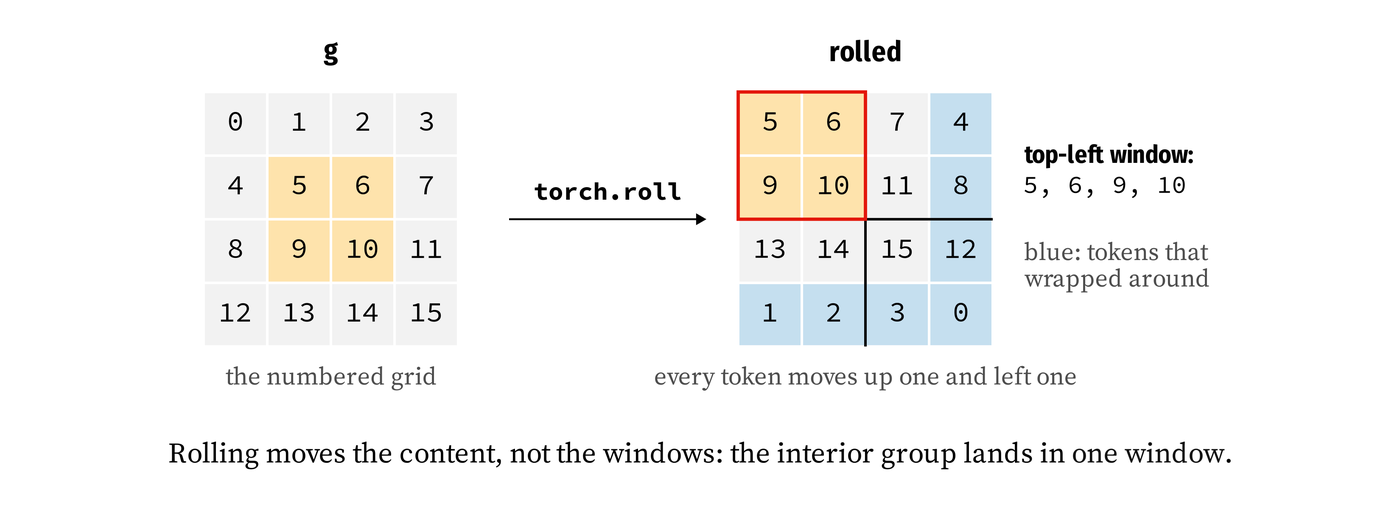

In [13]:
#@title torch.roll on the numbered grid
print(torch.roll(g, (-1, -1), dims=(1, 2))[0, :, :, 0])

tensor([[ 5,  6,  7,  4],
        [ 9, 10, 11,  8],
        [13, 14, 15, 12],
        [ 1,  2,  3,  0]])


On the real image, rolling by `SHIFT = 2` tokens moves the content by 4 pixels. The windows of the rolled grid now straddle the old boundaries. But the windows on the right and bottom edges now hold pieces that wrapped around from the far side of the image. Those pieces were not neighbors, so attention between them must be blocked.

**In pictures:** what the next cell does.

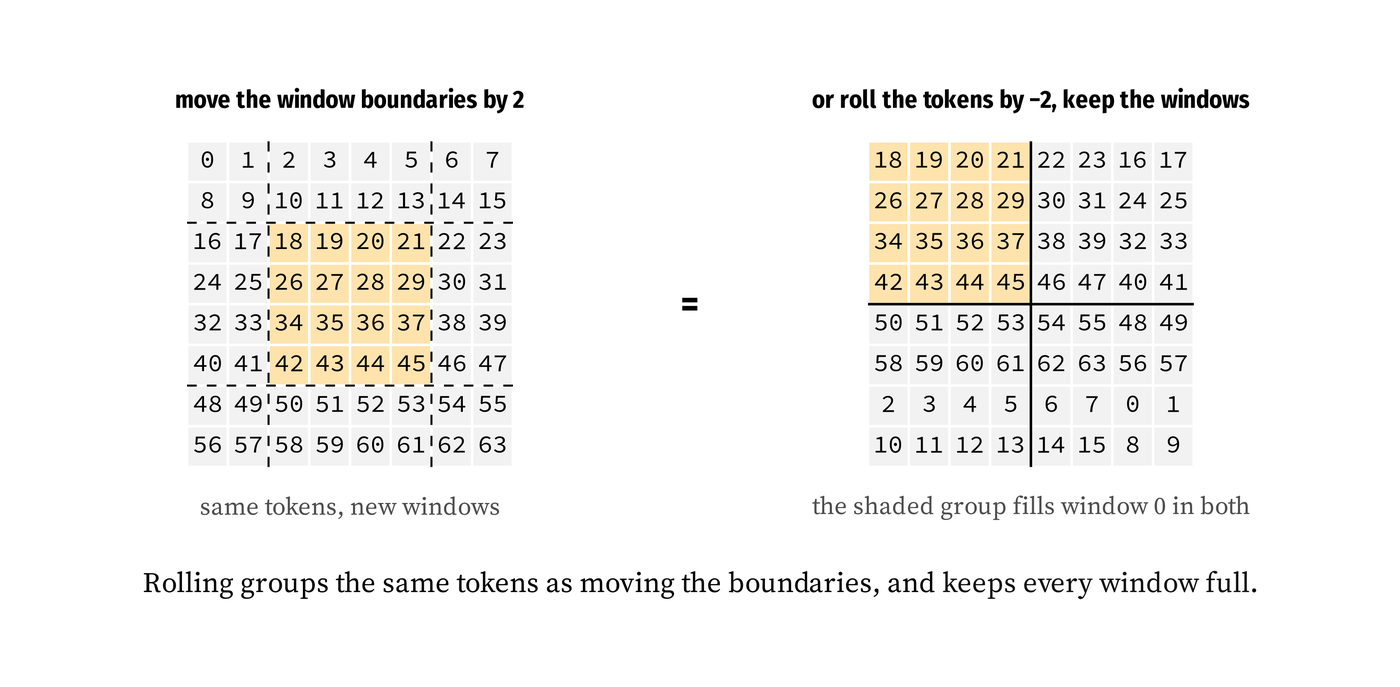

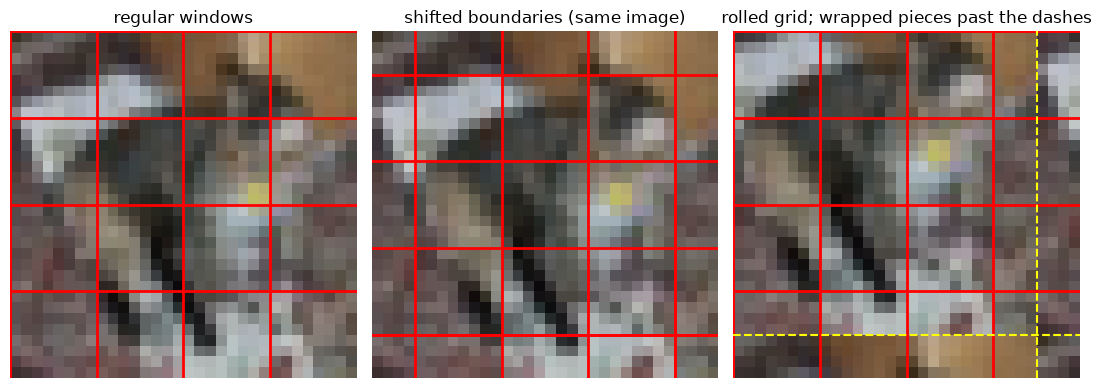

In [14]:
#@title Regular and shifted windows on the image
shifted_pixels = torch.roll(cat_image, (-SHIFT * PATCH_SIZE, -SHIFT * PATCH_SIZE), dims=(1, 2))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.9))
axes[0].imshow(denorm(cat_image)); draw_grid(axes[0], win_px, 'red', 2); axes[0].set_title('regular windows')
axes[1].imshow(denorm(cat_image)); draw_grid(axes[1], win_px, 'red', 2, offset=-SHIFT * PATCH_SIZE)
axes[1].set_title('shifted boundaries (same image)')
axes[2].imshow(denorm(shifted_pixels)); draw_grid(axes[2], win_px, 'red', 2)
axes[2].axhline(IMG_SIZE - SHIFT * PATCH_SIZE - .5, color='yellow', lw=1.5, ls='--')
axes[2].axvline(IMG_SIZE - SHIFT * PATCH_SIZE - .5, color='yellow', lw=1.5, ls='--')
axes[2].set_title('rolled grid; wrapped pieces past the dashes')
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

The middle and right pictures are the same computation seen two ways. Rolling the grid and keeping the windows fixed groups exactly the tokens that moved boundaries would group. Rolling is used because it keeps every window full and lets the same `window_partition` run unchanged.

### Region labels and the mask

To find the pairs that must not attend to each other, label every position of the rolled grid by the region it came from. The bands are: everything except the last window, the last window minus the shift, and the wrapped strip of width `SHIFT`. Three bands on each axis give nine regions. Two tokens may attend to each other only if they carry the same label (listing 4.6).

**In pictures:** what the next cell does.

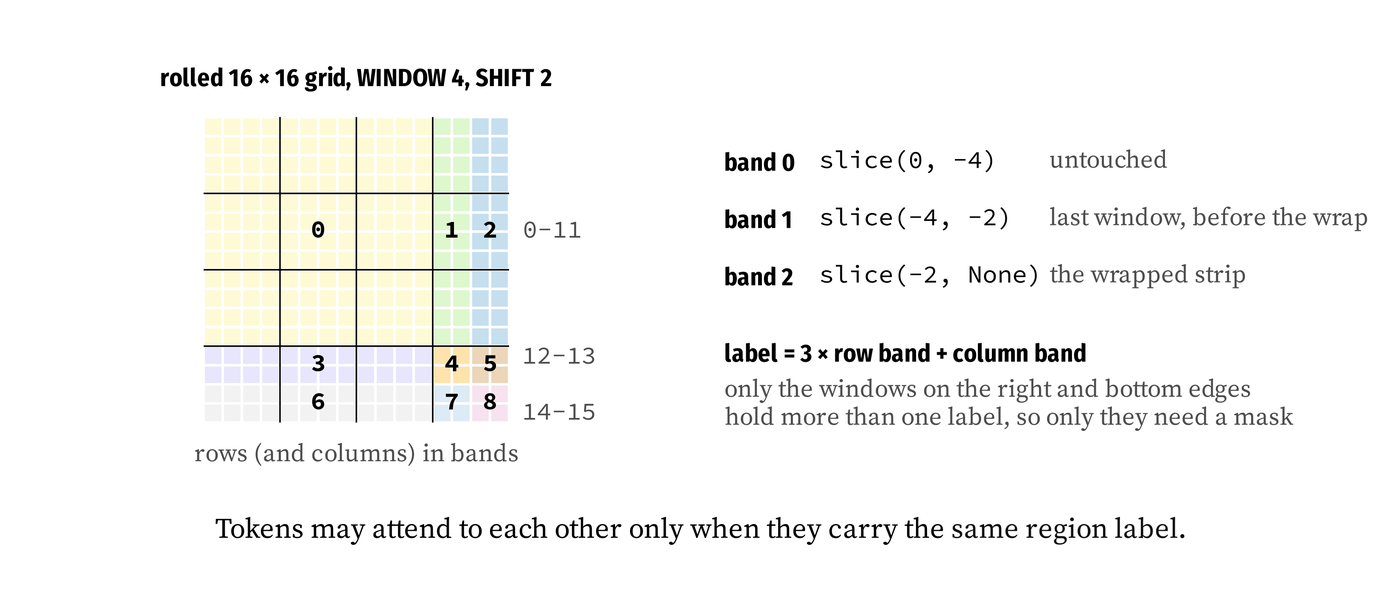

mask: (16, 16, 16)  [windows, 16 queries, 16 keys]


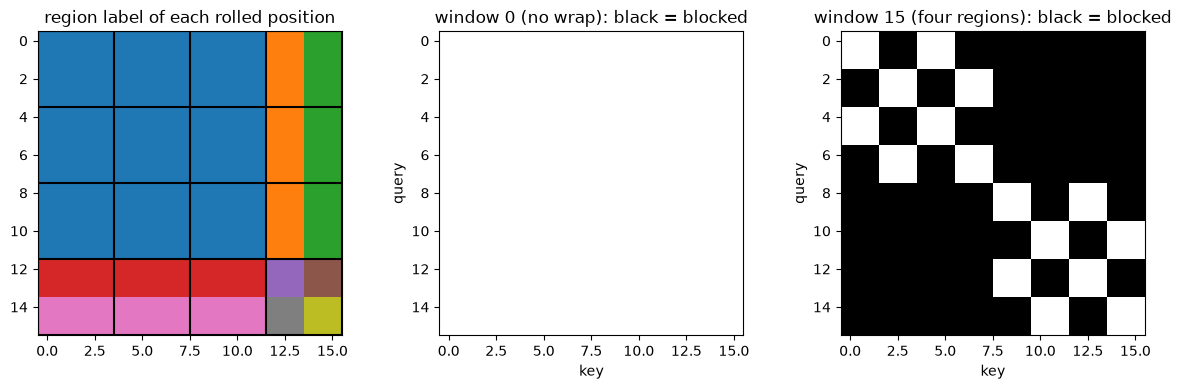

In [15]:
#@title region_labels and mask_from_regions
def region_labels(H, W, win, shift):
    labels = torch.zeros(1, H, W, 1, dtype=torch.long)
    # Mark three bands on each axis: interior, final unwrapped part, and wrapped strip.
    bands = (slice(0, -win), slice(-win, -shift), slice(-shift, None))
    for row_id, rows in enumerate(bands):
        for col_id, cols in enumerate(bands):
            labels[:, rows, cols] = 3 * row_id + col_id
    return labels

def mask_from_regions(labels, win):
    # Partition region labels exactly like tokens so their positions match.
    ids = window_partition(labels, win).squeeze(-1)
    query_labels = ids[:, :, None]
    key_labels = ids[:, None, :]
    # Block a query-key pair when the two region labels differ.
    blocked = query_labels != key_labels
    mask = torch.zeros(blocked.shape, device=ids.device)
    return mask.masked_fill(blocked, float('-inf'))

labels = region_labels(GRID, GRID, WINDOW, SHIFT)
mask = mask_from_regions(labels, WINDOW)
print('mask:', tuple(mask.shape), ' [windows, 16 queries, 16 keys]')
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].imshow(labels[0, :, :, 0], cmap='tab10', vmin=0, vmax=9)
for k in range(0, GRID + 1, WINDOW):
    axes[0].axhline(k - .5, color='k', lw=1.5); axes[0].axvline(k - .5, color='k', lw=1.5)
axes[0].set_title('region label of each rolled position')
for ax, w, name in [(axes[1], 0, 'window 0 (no wrap)'), (axes[2], 15, 'window 15 (four regions)')]:
    ax.imshow(torch.isinf(mask[w]), cmap='Greys', vmin=0, vmax=1); ax.set_title(f'{name}: black = blocked')
    ax.set_xlabel('key'); ax.set_ylabel('query')
plt.tight_layout(); plt.show()

Window 0 lies entirely inside one region, so its mask blocks nothing. Window 15, in the bottom-right corner, holds four regions, and three quarters of its pairs are blocked. Only the windows along the right and bottom edges need masking at all.

## 10. The Swin block

A Swin block is a pre-norm transformer block whose attention runs in windows. Blocks come in pairs: the first uses regular windows (W-MSA), the second shifted windows (SW-MSA). The shifted block rolls the grid before partitioning and rolls it back after `window_reverse`, so the shortcut adds each token's update at its original position (listing 4.8).

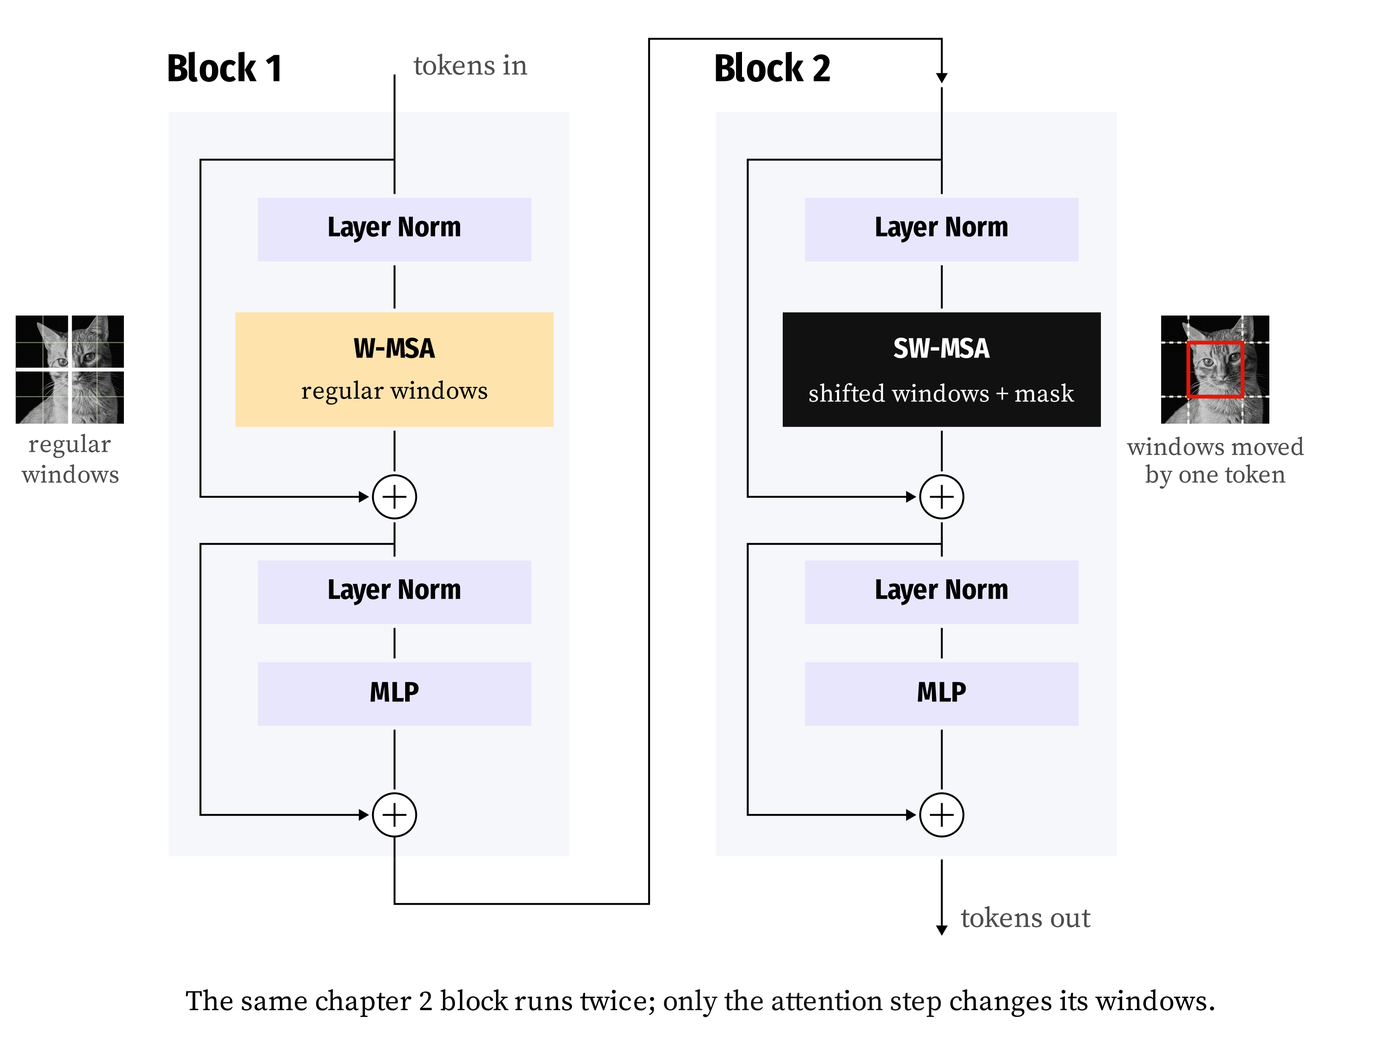

**In pictures:** what the next cell does.

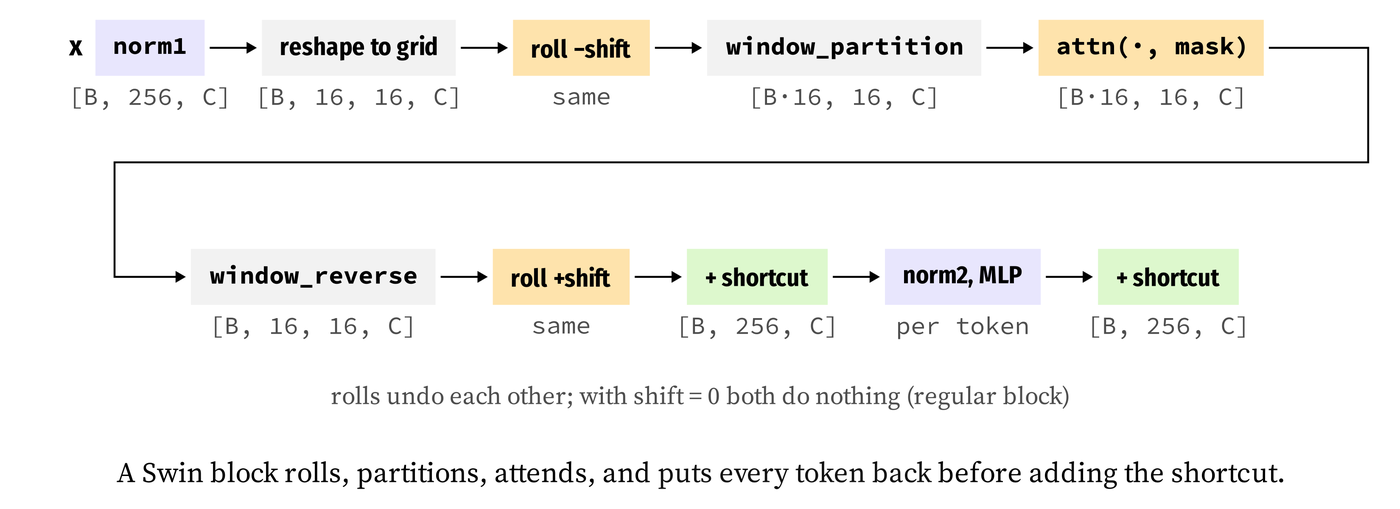

In [16]:
#@title SwinBlock
class SwinBlock(nn.Module):
    def __init__(self, dim, resolution, heads, win=WINDOW, shift=0):
        super().__init__()
        H, W = resolution
        self.grid_size = resolution
        # Limit the window to the grid size. A grid covered by one window needs no
        # shift.
        self.win = min(win, min(resolution))
        self.shift = 0 if min(resolution) <= win else shift
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attn = WindowAttention(dim, heads, self.win)
        self.mlp = nn.Sequential(nn.Linear(dim, MLP_RATIO * dim), nn.GELU(), nn.Linear(MLP_RATIO * dim, dim))
        mask = None
        if self.shift:
            mask = mask_from_regions(region_labels(H, W, self.win, self.shift), self.win)
        # Store the mask once for this grid, window size, and shift.
        self.register_buffer('mask', mask)
    def forward(self, x):
        B, N, C = x.shape
        H, W = self.grid_size
        shortcut = x
        grid = self.norm1(x).reshape(B, H, W, C)
        # Roll up and left before partitioning. A zero shift leaves the grid unchanged.
        grid = torch.roll(grid, (-self.shift, -self.shift), dims=(1, 2))
        windows = window_partition(grid, self.win)
        windows = self.attn(windows, self.mask)
        grid = window_reverse(windows, self.win, H, W)
        # Undo the roll so each update lines up with its original shortcut position.
        grid = torch.roll(grid, (self.shift, self.shift), dims=(1, 2))
        x = shortcut + grid.reshape(B, N, C)
        return x + self.mlp(self.norm2(x))

A quick check: the block keeps the shape, and with `shift = 0` it must not mix tokens from different windows. We test the second claim directly: change one token and see which outputs move.

**In pictures:** what the next cell does.

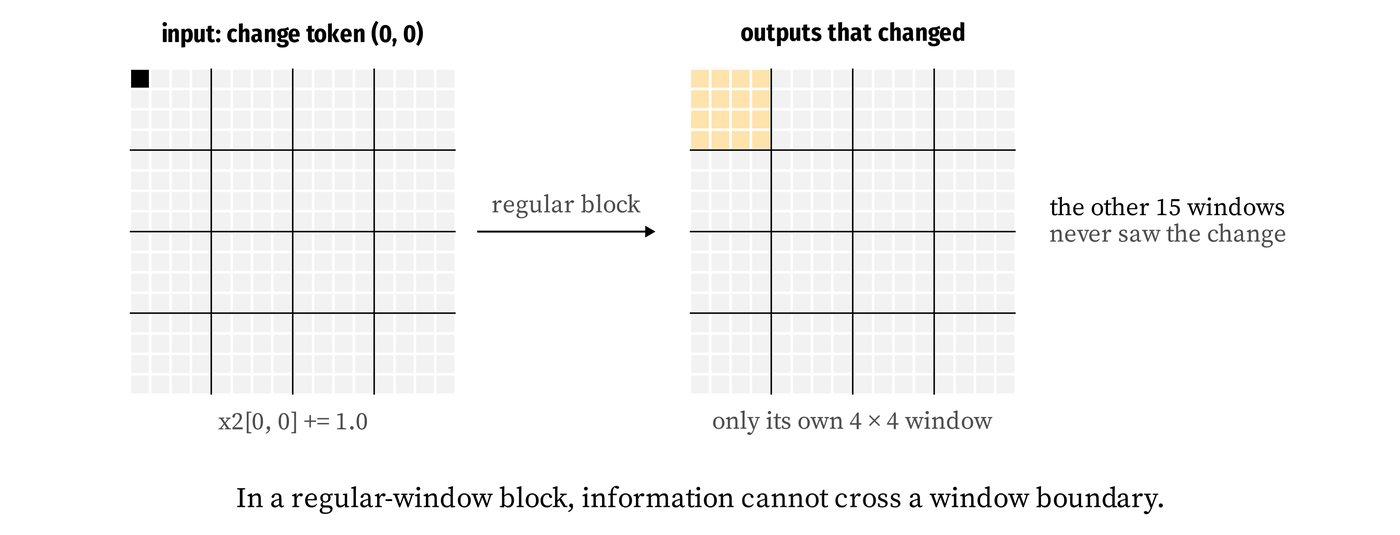

In [17]:
#@title Shape check and a locality test
block = SwinBlock(EMBED_DIM, (GRID, GRID), HEADS[0]).eval()
x = torch.randn(1, GRID * GRID, EMBED_DIM)
y = block(x)
print('shape:', tuple(x.shape), '->', tuple(y.shape))
x2 = x.clone(); x2[0, 0] += 1.0                                            # change token (0, 0)
moved = (block(x2) - y).abs().sum(-1)[0].reshape(GRID, GRID) > 1e-6
print('outputs that changed (regular block):')
print(moved[:6, :6].int())

shape: (1, 256, 64) -> (1, 256, 64)
outputs that changed (regular block):
tensor([[1, 1, 1, 1, 0, 0],
        [1, 0, 0, 1, 0, 0],
        [1, 1, 1, 1, 0, 0],
        [1, 1, 0, 1, 0, 0],
        [0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0]], dtype=torch.int32)


Only the 4 x 4 window that contains token (0, 0) changes. Information has not crossed a window boundary. Section 13 shows what the shifted block does to this picture.

## 11. Patch merging

Between stages, patch merging joins every 2 x 2 group of neighboring tokens into one token. It concatenates the four feature vectors (4C), normalizes them, and projects them to 2C. The grid's side halves and the width doubles (listing 4.9).

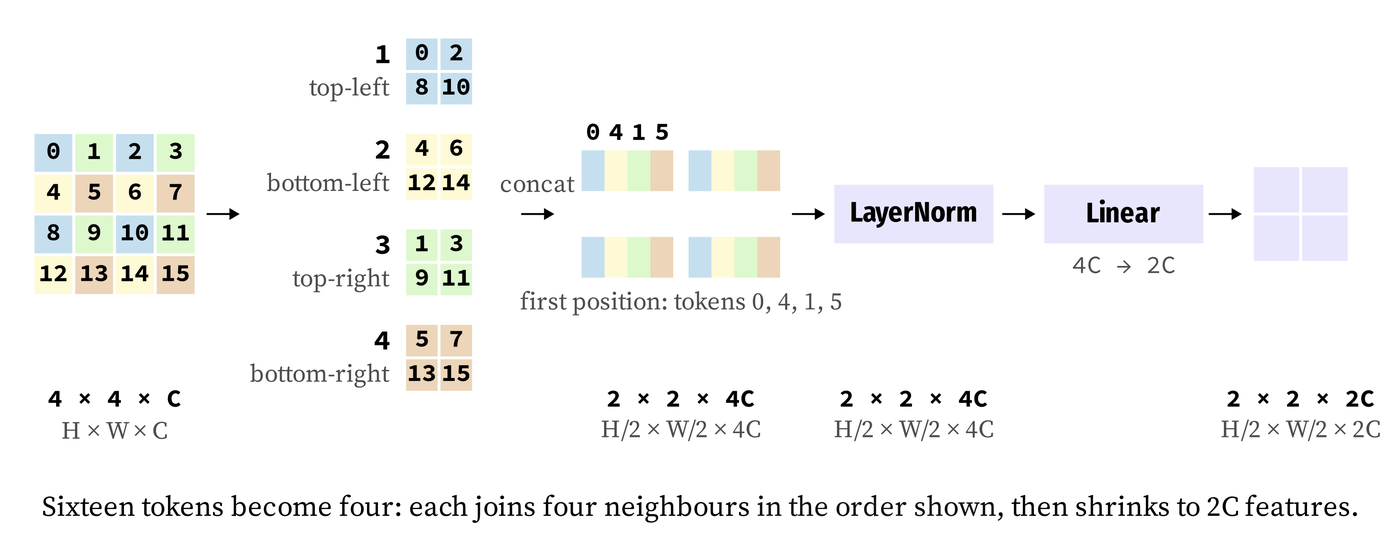

**In pictures:** what the next cell does.

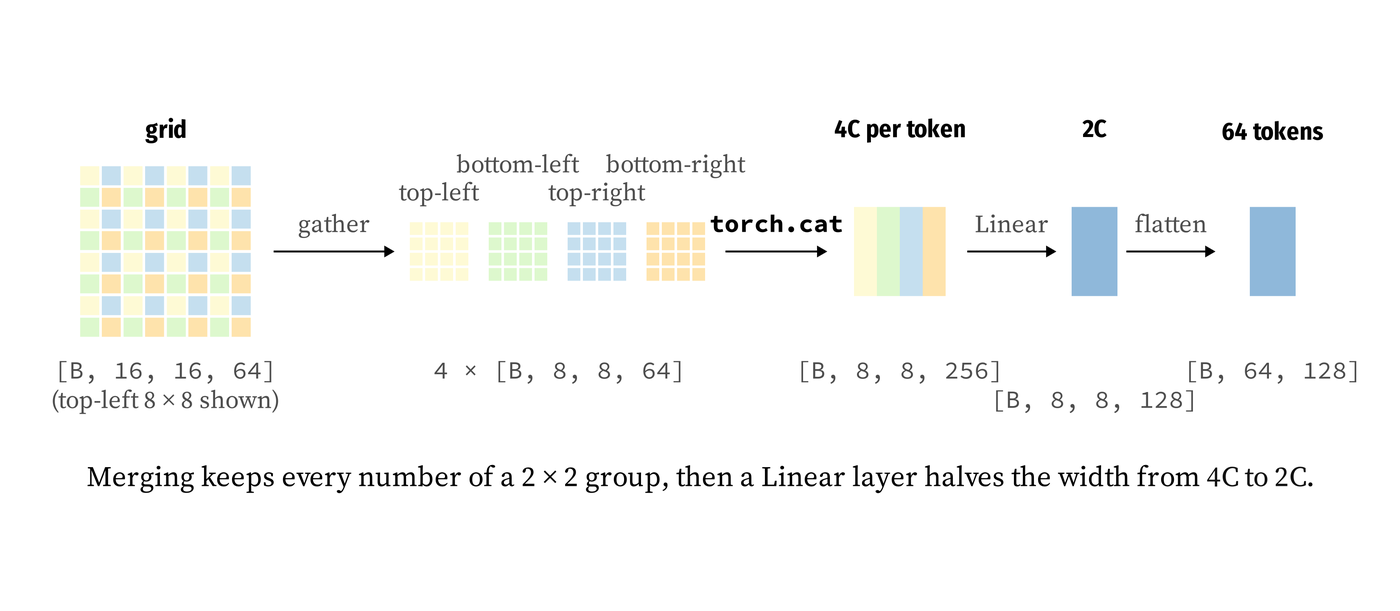

In [18]:
#@title PatchMerging
def gather_neighbors(grid):
    top_left = grid[:, 0::2, 0::2]
    bottom_left = grid[:, 1::2, 0::2]
    top_right = grid[:, 0::2, 1::2]
    bottom_right = grid[:, 1::2, 1::2]
    # Join neighbors in this order: top-left, bottom-left, top-right, bottom-right. The
    # numbered grid starts with 0, 4, 1, 5.
    return torch.cat([top_left, bottom_left, top_right, bottom_right], dim=-1)

class PatchMerging(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.norm = nn.LayerNorm(4 * dim)
        # Reduce the joined 4C features to 2C. Each output token replaces a 2 x 2 group.
        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)
    def forward(self, x, H, W):
        grid = x.reshape(x.shape[0], H, W, -1)
        merged = self.reduction(self.norm(gather_neighbors(grid)))
        return merged.flatten(1, 2), H // 2, W // 2

print('numbered grid, first merged token gathers:', gather_neighbors(g)[0, 0, 0].tolist())
merged, H, W = PatchMerging(EMBED_DIM)(torch.randn(2, GRID * GRID, EMBED_DIM), GRID, GRID)
print('merge:', (2, GRID * GRID, EMBED_DIM), '->', tuple(merged.shape), f' grid {H} x {W}')

numbered grid, first merged token gathers: [0, 4, 1, 5]
merge: (2, 256, 64) -> (2, 64, 128)  grid 8 x 8


## 12. The complete model

Now everything fits together. Three stages, each a pair of blocks, with patch merging between them:

| Stage | Grid | Tokens | Features | Windows per image | Blocks |
| --- | --- | ---: | ---: | ---: | --- |
| 1 | 16 x 16 | 256 | 64 | 16 | regular, shifted |
| merge | | | | | 2 x 2 groups, 256 -> 128 features |
| 2 | 8 x 8 | 64 | 128 | 4 | regular, shifted |
| merge | | | | | 2 x 2 groups, 512 -> 256 features |
| 3 | 4 x 4 | 16 | 256 | 1 | regular, regular (one window covers the grid) |

The classifier averages the final 16 tokens and applies a linear layer. Swin has no class token.

**In pictures:** what the next cell does.

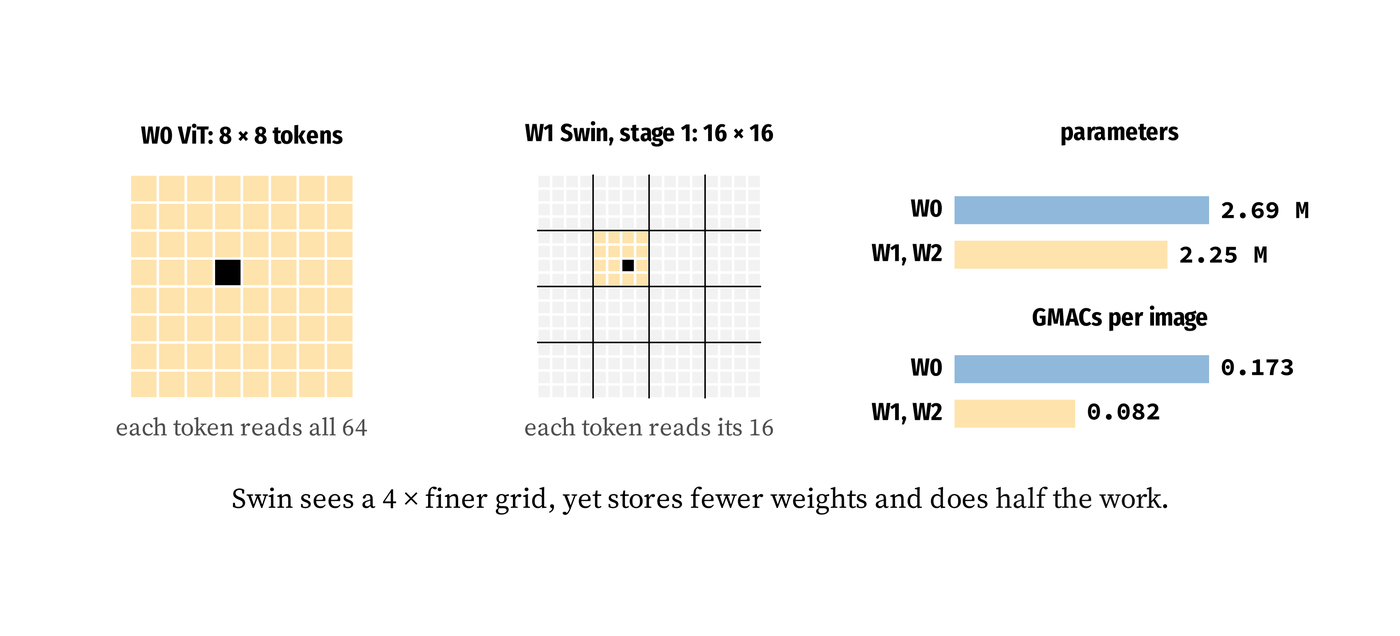

In [19]:
#@title SwinCIFAR and the ViT baseline
def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.trunc_normal_(m.weight, std=0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)

class SwinCIFAR(nn.Module):
    def __init__(self, shift=SHIFT):
        super().__init__()
        self.patch = PatchEmbed()
        self.stages, self.merges = nn.ModuleList(), nn.ModuleList()
        dim, side = EMBED_DIM, GRID
        for s, (depth, heads) in enumerate(zip(DEPTHS, HEADS)):
            self.stages.append(nn.Sequential(*[
                # Alternate regular and shifted windows. Setting shift=0 disables
                # shifting.
                SwinBlock(dim, (side, side), heads, WINDOW, shift if k % 2 else 0)
                for k in range(depth)]))
            if s < len(DEPTHS) - 1:
                # Merge patches between stages, but not after the final stage.
                self.merges.append(PatchMerging(dim))
                dim, side = 2 * dim, side // 2
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, CLASSES)
        self.apply(init_weights)
    def forward(self, images):
        x, side = self.patch(images), GRID
        for s, stage in enumerate(self.stages):
            x = stage(x)
            if s < len(self.merges):
                x, side, _ = self.merges[s](x, side, side)
        # Average the final tokens instead of reading a CLS token.
        return self.head(self.norm(x).mean(dim=1))

class ViT(nn.Module):
    '''The W0 baseline: global attention on an 8 x 8 grid, as in chapter 3.'''
    def __init__(self):
        super().__init__()
        self.proj = nn.Conv2d(CHANNELS, VIT_DIM, VIT_PATCH, VIT_PATCH)
        n = (IMG_SIZE // VIT_PATCH) ** 2
        self.cls = nn.Parameter(torch.zeros(1, 1, VIT_DIM))
        self.pos = nn.Parameter(torch.randn(1, n + 1, VIT_DIM) * 0.02)
        layer = nn.TransformerEncoderLayer(VIT_DIM, VIT_HEADS, MLP_RATIO * VIT_DIM, dropout=0.0,
                                           activation='gelu', batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, VIT_DEPTH, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(VIT_DIM)
        self.head = nn.Linear(VIT_DIM, CLASSES)
    def forward(self, images):
        x = self.proj(images).flatten(2).transpose(1, 2)
        x = torch.cat([self.cls.expand(x.size(0), -1, -1), x], dim=1) + self.pos
        return self.head(self.norm(self.blocks(x))[:, 0])

### Follow one batch through the stages

Forward hooks print each stage's output during a single pass.

**In pictures:** what the next cell does.

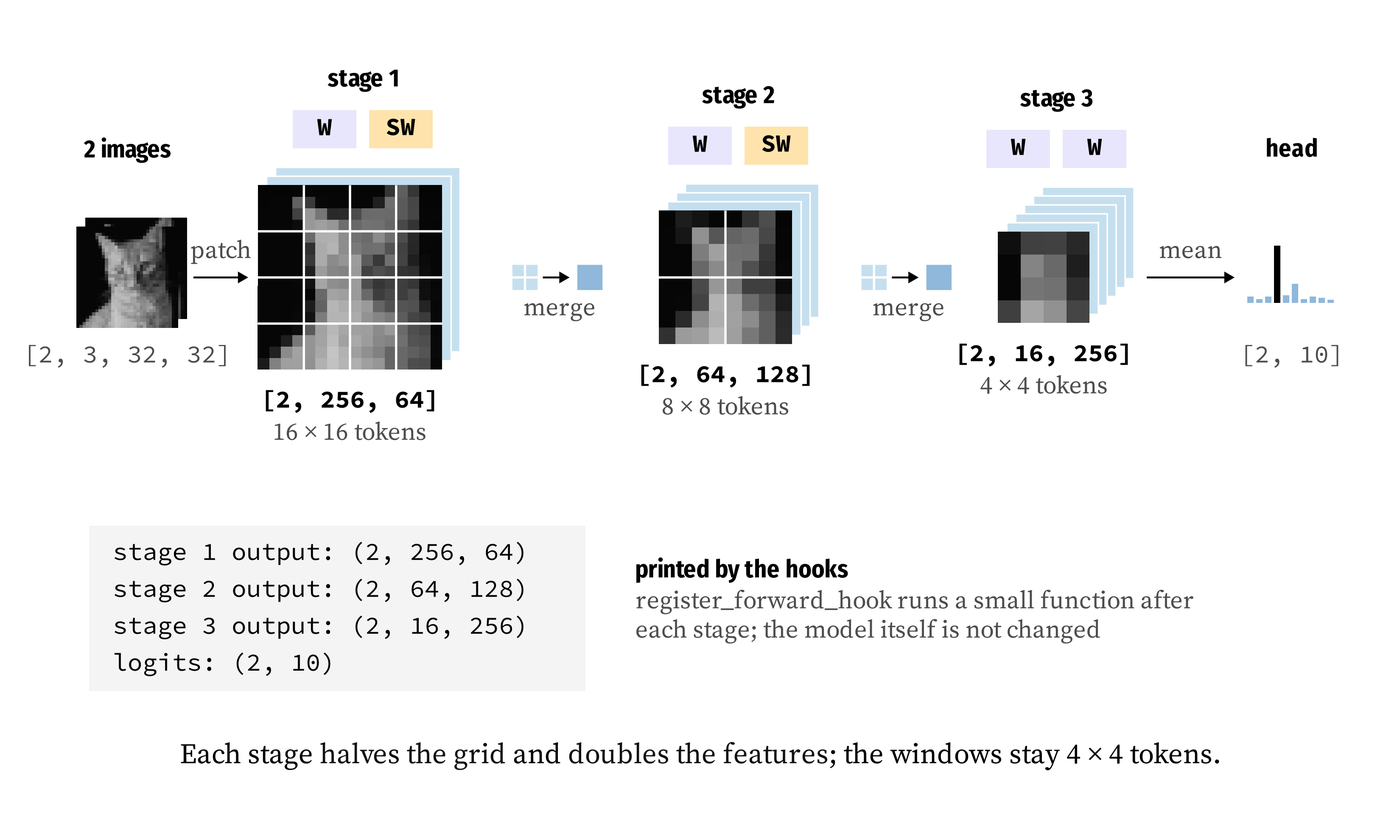

In [20]:
#@title Trace the shapes
swin = SwinCIFAR().eval()
hooks = [stage.register_forward_hook(lambda m, i, o, s=s: print(f'stage {s + 1} output:', tuple(o.shape)))
         for s, stage in enumerate(swin.stages)]
with torch.no_grad():
    print('logits:', tuple(swin(torch.randn(2, CHANNELS, IMG_SIZE, IMG_SIZE)).shape))
for h in hooks:
    h.remove()
print('shift per block:', [[b.shift for b in st] for st in swin.stages])

stage 1 output: (2, 256, 64)
stage 2 output: (2, 64, 128)
stage 3 output: (2, 16, 256)
logits: (2, 10)
shift per block: [[0, 2], [0, 2], [0, 0]]


### Size and compute

Parameters measure the stored weights; GMACs, billions of multiply-accumulate operations per image, estimate the work of one forward pass.

In [21]:
#@title Parameters and GMACs
def count_params(model):
    return sum(p.numel() for p in model.parameters())

def count_gmacs(model):
    model.eval()
    with FlopCounterMode(display=False) as counter:
        model(torch.randn(1, CHANNELS, IMG_SIZE, IMG_SIZE))
    return counter.get_total_flops() / 2e9

SIZES = {}
for key, make in [('W0_vit', ViT), ('W1_swin', SwinCIFAR), ('W2_swin_noshift', lambda: SwinCIFAR(shift=0))]:
    m = make()
    SIZES[key] = (count_params(m), count_gmacs(m))
    print(f'{key:16s} {SIZES[key][0] / 1e6:5.2f}M params   {SIZES[key][1]:.3f} GMACs per image')

W0_vit            2.69M params   0.173 GMACs per image
W1_swin           2.25M params   0.082 GMACs per image
W2_swin_noshift   2.25M params   0.082 GMACs per image


Swin works on four times as many first-stage tokens as the ViT, yet needs fewer parameters and fewer operations. The windows keep stage 1 cheap, and the merges shrink the grid before the wide layers. W1 and W2 are the same size: shifting adds no weights.

## 13. Watching information spread

How far can information travel through a stack of blocks? We can measure it directly. Take an untrained stage-1 stack, pick one output token, and ask which input tokens affect it: the gradient of that output with respect to every input is nonzero exactly where there is a path.

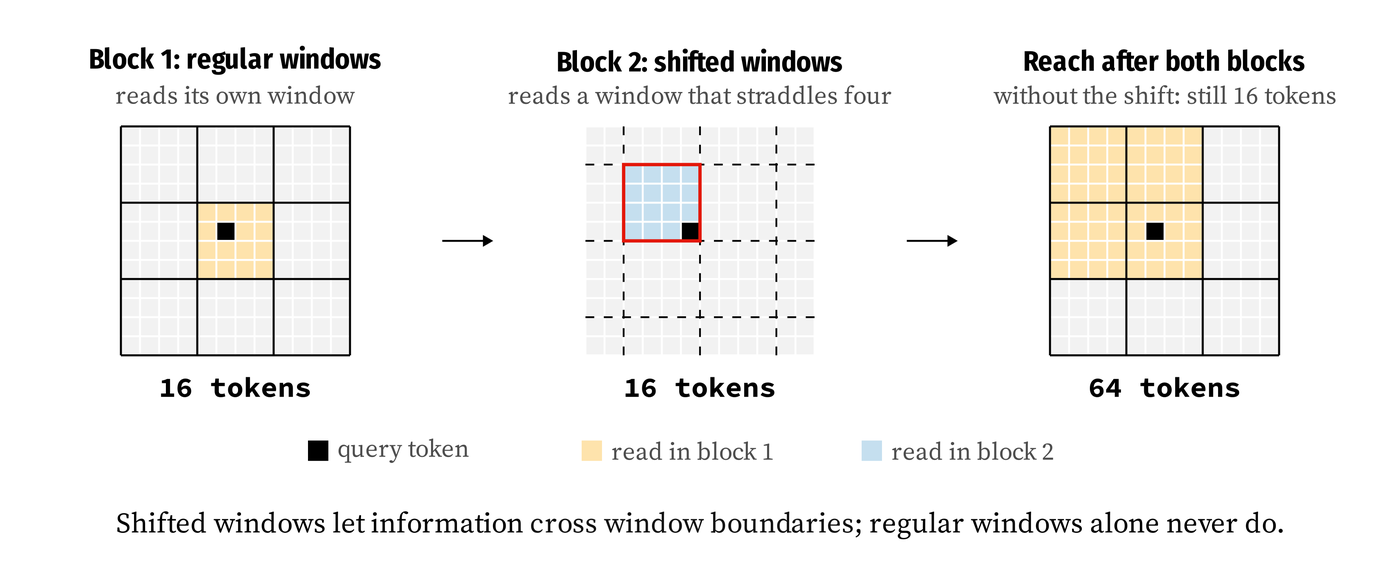

The cell below computes these maps for 1 to 4 blocks, once with the shift (W, SW, W, SW) and once without (W, W, W, W).

**In pictures:** what the next cell does.

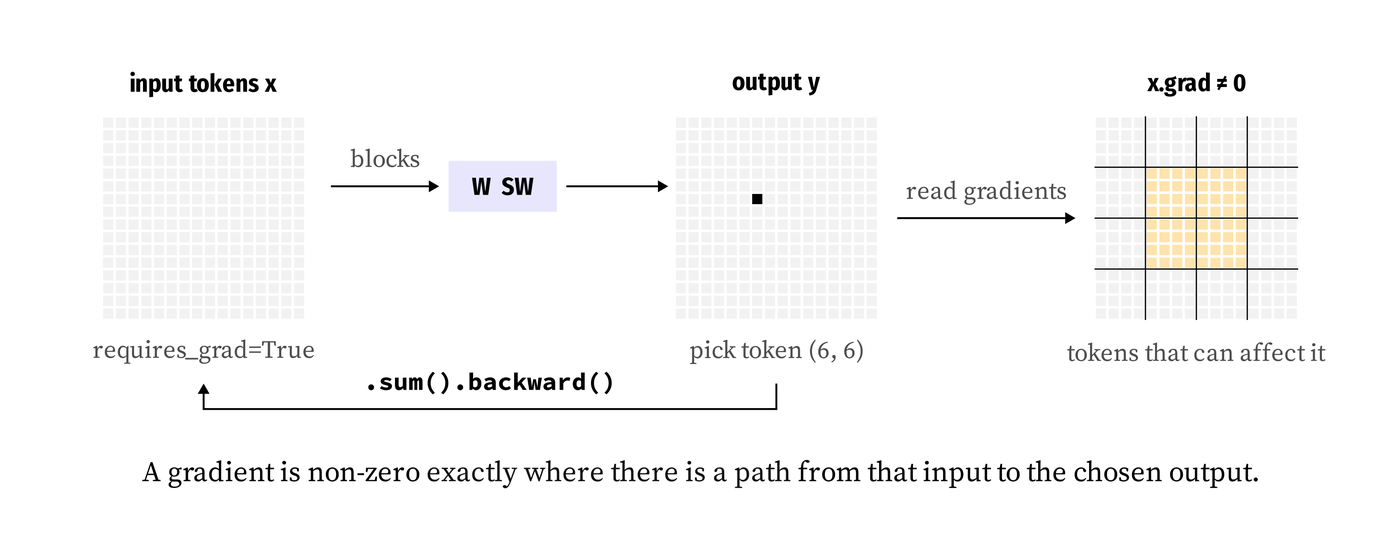

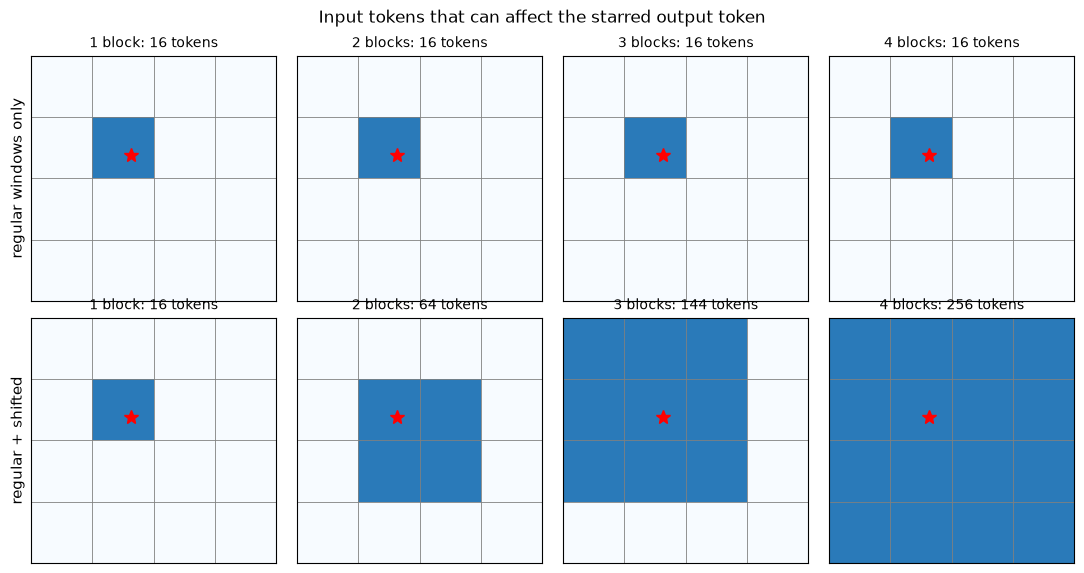

In [22]:
#@title Influence maps with and without the shift
def influence(blocks, row, col):
    x = torch.randn(1, GRID * GRID, EMBED_DIM, requires_grad=True)
    y = x
    for block in blocks:
        y = block(y)
    # Backpropagate from the selected output token to the input tokens.
    y[0, row * GRID + col].sum().backward()
    return x.grad[0].norm(dim=-1).reshape(GRID, GRID)

torch.manual_seed(0)
shifted_stack = [SwinBlock(EMBED_DIM, (GRID, GRID), HEADS[0], WINDOW, SHIFT if k % 2 else 0).eval() for k in range(4)]
regular_stack = [SwinBlock(EMBED_DIM, (GRID, GRID), HEADS[0], WINDOW, 0).eval() for k in range(4)]
row, col = 6, 6
fig, axes = plt.subplots(2, 4, figsize=(11, 5.8))
for r, (name, stack) in enumerate([('regular windows only', regular_stack), ('regular + shifted', shifted_stack)]):
    for k in range(4):
        # Mark input tokens with a nonzero gradient in this probe.
        reach = influence(stack[:k + 1], row, col) > 0
        ax = axes[r, k]
        ax.imshow(reach, cmap='Blues', vmin=0, vmax=1.4)
        ax.plot(col, row, 'r*', ms=10)
        for b in range(0, GRID + 1, WINDOW):
            ax.axhline(b - .5, color='grey', lw=.6); ax.axvline(b - .5, color='grey', lw=.6)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f'{k + 1} block{"s" if k else ""}: {int(reach.sum())} tokens', fontsize=10)
    axes[r, 0].set_ylabel(name, fontsize=11)
plt.suptitle('Input tokens that can affect the starred output token', fontsize=12)
plt.tight_layout(); plt.show()

Without the shift, the starred token sees its own 4 x 4 window, and that never changes: 16 tokens after one block and still 16 after four. With the shift, the reach grows with every block after the first: 16, 64, 144, and then all 256 tokens. Read the maps from the output backward: the last block reads one window, each token in that window read a window in the block before, and so on. Once regular and shifted windows alternate, those windows overlap and the reach spreads. These counts depend only on the window layout, not on the weights, so you will get the same numbers.

This is the whole reason for shifted windows. W2, the model without the shift, can still mix windows, but only through patch merging after stage 1 has finished.

## 14. Training

One loop trains all three models; only the model changes. We use AdamW, a linear warmup, then a cosine decay, gradient clipping at 1, and label smoothing, the same recipe as the DeiT notebook's students.

In [23]:
#@title Training loop
def autocast():
    '''Mixed precision on CUDA GPUs; plain float32 on MPS and CPU.'''
    return torch.autocast('cuda', dtype=torch.float16) if device == 'cuda' else nullcontext()

@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with autocast():
            correct += (model(x).argmax(1) == y).sum().item()
        total += y.numel()
    return 100 * correct / total

def warmup_cosine(total_steps, warmup_steps):
    def factor(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * progress))
    return factor

def train_run(key, make_model):
    path = f'{CKPT_DIR}/{key}.pt'
    torch.manual_seed(SEED)
    model = make_model().to(device)
    if os.path.exists(path):
        ckpt = torch.load(path, map_location=device)
        model.load_state_dict(ckpt['model'])
        print('loaded', path)
        return model, ckpt['history']
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    steps = EPOCHS * len(train_dl)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, warmup_cosine(steps, WARMUP_EPOCHS * len(train_dl)))
    scaler = torch.amp.GradScaler('cuda', enabled=(device == 'cuda'))
    history, best, best_state, start = [], -1.0, None, time.time()
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0.0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            with autocast():
                loss = F.cross_entropy(model(x), y, label_smoothing=LABEL_SMOOTHING)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            total_loss += loss.item()
        val = accuracy(model, val_dl)
        history.append({'loss': total_loss / len(train_dl), 'val': val})
        if val > best:
            best, best_state = val, {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f'{key} epoch {epoch + 1:2d}/{EPOCHS}  loss {history[-1]["loss"]:.3f}  val {val:5.1f}%  ({time.time() - start:.0f}s)')
    model.load_state_dict(best_state)
    torch.save({'model': best_state, 'history': history, 'minutes': (time.time() - start) / 60}, path)
    return model, history

### Train W0, W1, and W2

This is the longest cell. Each line of output is one epoch.

In [24]:
#@title Train the three models
EXPERIMENTS = {
    'W0_vit':          ViT,
    'W1_swin':         SwinCIFAR,
    'W2_swin_noshift': lambda: SwinCIFAR(shift=0),
}
models, histories = {}, {}
for key, make_model in EXPERIMENTS.items():
    models[key], histories[key] = train_run(key, make_model)

W0_vit epoch  1/30  loss 2.093  val  37.1%  (13s)
W0_vit epoch  2/30  loss 1.934  val  40.4%  (25s)
W0_vit epoch  3/30  loss 1.853  val  47.2%  (36s)
W0_vit epoch  4/30  loss 1.813  val  49.2%  (47s)
W0_vit epoch  5/30  loss 1.769  val  52.4%  (58s)
W0_vit epoch  6/30  loss 1.726  val  55.0%  (69s)
W0_vit epoch  7/30  loss 1.670  val  57.2%  (80s)
W0_vit epoch  8/30  loss 1.631  val  57.7%  (92s)
W0_vit epoch  9/30  loss 1.592  val  61.6%  (103s)
W0_vit epoch 10/30  loss 1.551  val  64.5%  (114s)
W0_vit epoch 11/30  loss 1.511  val  64.4%  (126s)
W0_vit epoch 12/30  loss 1.469  val  65.5%  (137s)
W0_vit epoch 13/30  loss 1.440  val  67.8%  (148s)
W0_vit epoch 14/30  loss 1.409  val  69.7%  (160s)
W0_vit epoch 15/30  loss 1.373  val  71.0%  (171s)
W0_vit epoch 16/30  loss 1.349  val  71.4%  (183s)
W0_vit epoch 17/30  loss 1.319  val  72.9%  (194s)
W0_vit epoch 18/30  loss 1.302  val  74.5%  (205s)
W0_vit epoch 19/30  loss 1.271  val  74.6%  (217s)
W0_vit epoch 20/30  loss 1.248  val  76

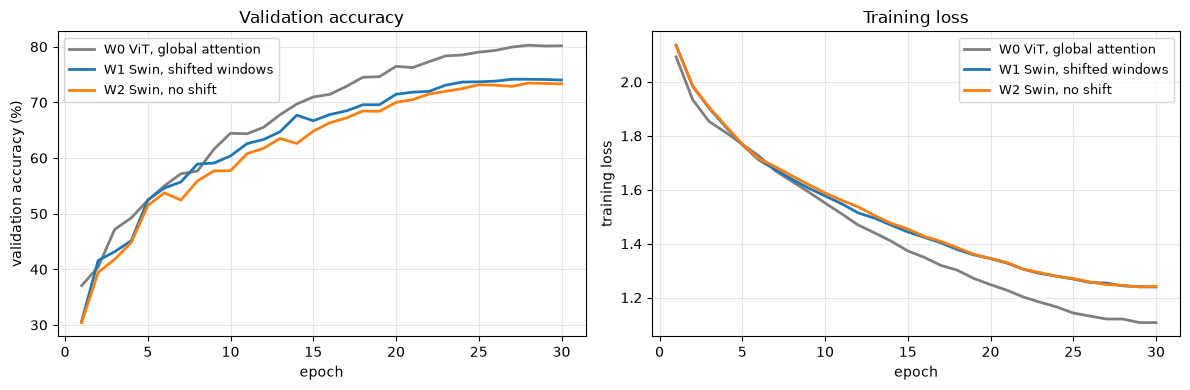

In [25]:
#@title Learning curves
STYLE = {'W0_vit': ('#7f7f7f', 'W0 ViT, global attention'),
         'W1_swin': ('#1f77b4', 'W1 Swin, shifted windows'),
         'W2_swin_noshift': ('#ff7f0e', 'W2 Swin, no shift')}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for key, h in histories.items():
    color, label = STYLE[key]
    epochs = range(1, len(h) + 1)
    a1.plot(epochs, [e['val'] for e in h], color=color, lw=2, label=label)
    a2.plot(epochs, [e['loss'] for e in h], color=color, lw=2, label=label)
a1.set(xlabel='epoch', ylabel='validation accuracy (%)', title='Validation accuracy')
a2.set(xlabel='epoch', ylabel='training loss', title='Training loss')
for a in (a1, a2):
    a.grid(alpha=.3); a.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 15. Test-set comparison

We measure test accuracy once, and speed as images per second on this device. The timing runs a few warm-up batches first and synchronizes the device, so it measures finished work rather than queued work.

**In pictures:** what the next cell does.

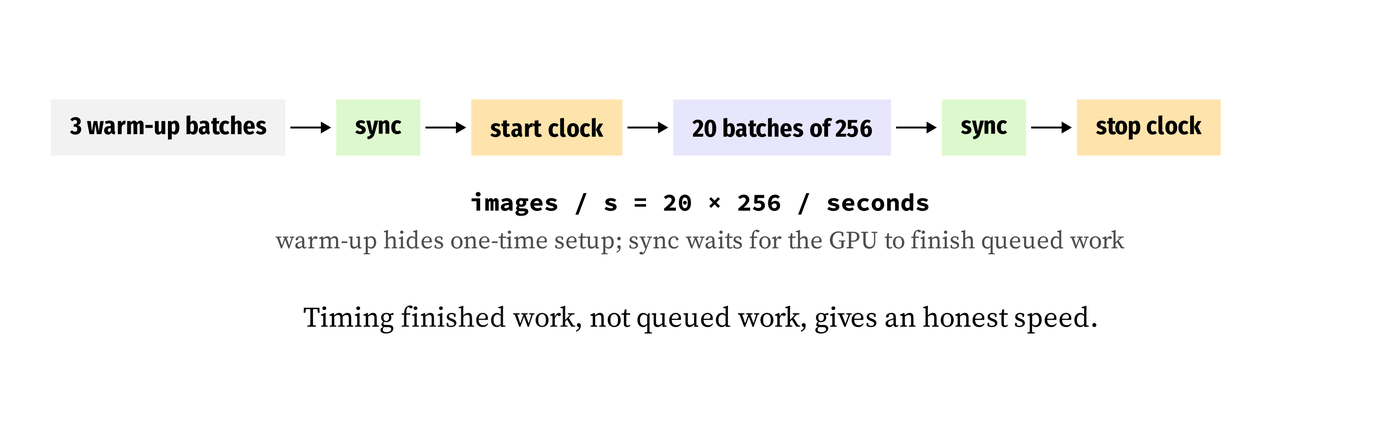

In [26]:
#@title Test accuracy and throughput
def sync():
    if device == 'cuda':
        torch.cuda.synchronize()
    elif device == 'mps':
        torch.mps.synchronize()

@torch.no_grad()
def throughput(model, batches=20, batch_size=256):
    model.eval()
    x = torch.randn(batch_size, CHANNELS, IMG_SIZE, IMG_SIZE, device=device)
    for _ in range(3):
        model(x)
    sync(); start = time.time()
    for _ in range(batches):
        model(x)
    sync()
    return batches * batch_size / (time.time() - start)

RESULTS = {}
print(f'{"model":28s} {"params":>7s} {"GMACs":>6s} {"test top-1":>10s} {"images/s":>9s} {"train min":>9s}')
for key, model in models.items():
    acc, ips = accuracy(model, test_dl), throughput(model)
    minutes = torch.load(f'{CKPT_DIR}/{key}.pt', map_location='cpu')['minutes']
    RESULTS[key] = {'params': SIZES[key][0], 'gmacs': SIZES[key][1], 'test': acc, 'ips': ips, 'minutes': minutes}
    print(f'{STYLE[key][1]:28s} {SIZES[key][0] / 1e6:6.2f}M {SIZES[key][1]:6.3f} {acc:9.1f}% {ips:9,.0f} {minutes:9.1f}')
json.dump(RESULTS, open(f'{CKPT_DIR}/results.json', 'w'), indent=1)

model                         params  GMACs test top-1  images/s train min
W0 ViT, global attention       2.69M  0.173      79.5%     5,783       5.7
W1 Swin, shifted windows       2.25M  0.082      73.2%     7,770       6.3
W2 Swin, no shift              2.25M  0.082      72.5%     7,773       6.2


### Reading the table

| Column | What to look for |
| --- | --- |
| **params** | Swin stores fewer weights than the ViT, even though it has three stages |
| **GMACs** | Swin also does less work per image, despite a four times finer first grid |
| **test top-1** | The effect of local windows and the hierarchy on a small dataset, and the effect of the shift (W1 against W2) |
| **images/s** | Real speed on this device. Window partitioning, rolls, and masks add memory traffic that GMACs do not count, so Swin's speed advantage is smaller than its GMACs advantage, and on some hardware it is slower |

**In our run:** Swin needed 2.1x fewer GMACs but ran only 1.34x faster (7,770 against 5,783 images per second), and it was 6.3 points less accurate than the ViT. W1 and W2 cost exactly the same; the shift bought 0.7 points.

## 16. Inside the trained Swin

### Learned relative-position biases

Each head of each block learned a 7 x 7 table of biases, one number per relative offset. The center is offset (0, 0), the query itself. A high value at an offset means "attend more to keys at this offset".

**In pictures:** what the next cell does.

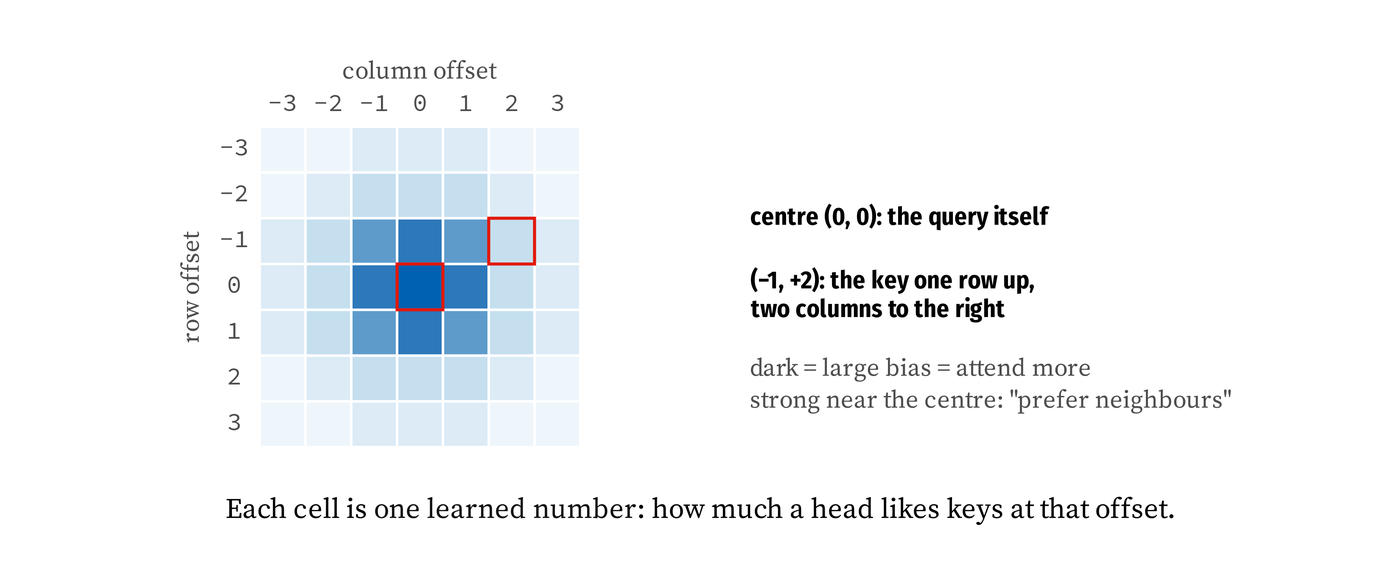

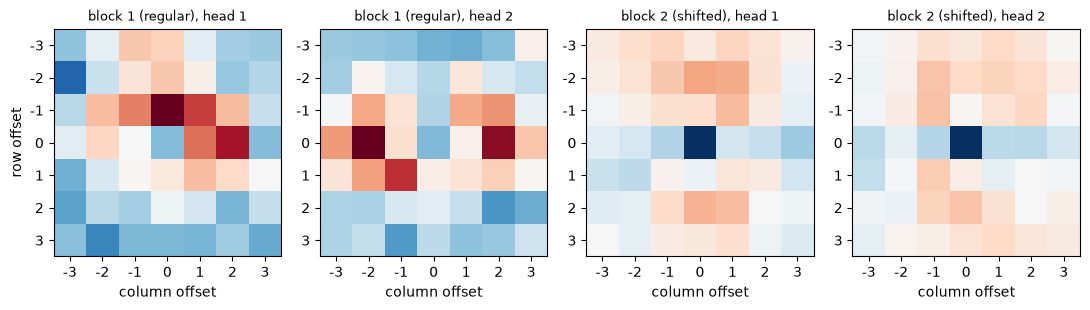

In [27]:
#@title Relative-position bias tables of stage 1
swin = models['W1_swin']
fig, axes = plt.subplots(1, 4, figsize=(11, 3.1))
k = 0
for b, block in enumerate(swin.stages[0]):
    for h in range(block.attn.heads):
        t = block.attn.table[h].detach().float().cpu()
        im = axes[k].imshow(t, cmap='RdBu_r', vmin=-t.abs().max(), vmax=t.abs().max())
        axes[k].set_title(f'block {b + 1} ({"shifted" if block.shift else "regular"}), head {h + 1}', fontsize=9)
        axes[k].set_xticks(range(7)); axes[k].set_xticklabels(range(-3, 4))
        axes[k].set_yticks(range(7)); axes[k].set_yticklabels(range(-3, 4))
        axes[k].set_xlabel('column offset'); k += 1
axes[0].set_ylabel('row offset')
plt.tight_layout(); plt.show()

In our run the two blocks learned different habits. In block 1, both heads give their largest biases (red) to keys one or two steps away, mostly in the row above and to the sides, and negative biases (blue) to far offsets. In block 2, the centre is strongly negative: those heads avoid the query's own position and spread attention to its neighbours. Nothing told the model to do this; the tables started as small random numbers.

### Window attention on a test image

For every window of stage 1's first block, we take the token at row 1, column 1 inside the window as the query and draw its attention weights over its own 4 x 4 window. Each window gets its own small heat map: attention never leaves the window.

**In pictures:** what the next cell does.

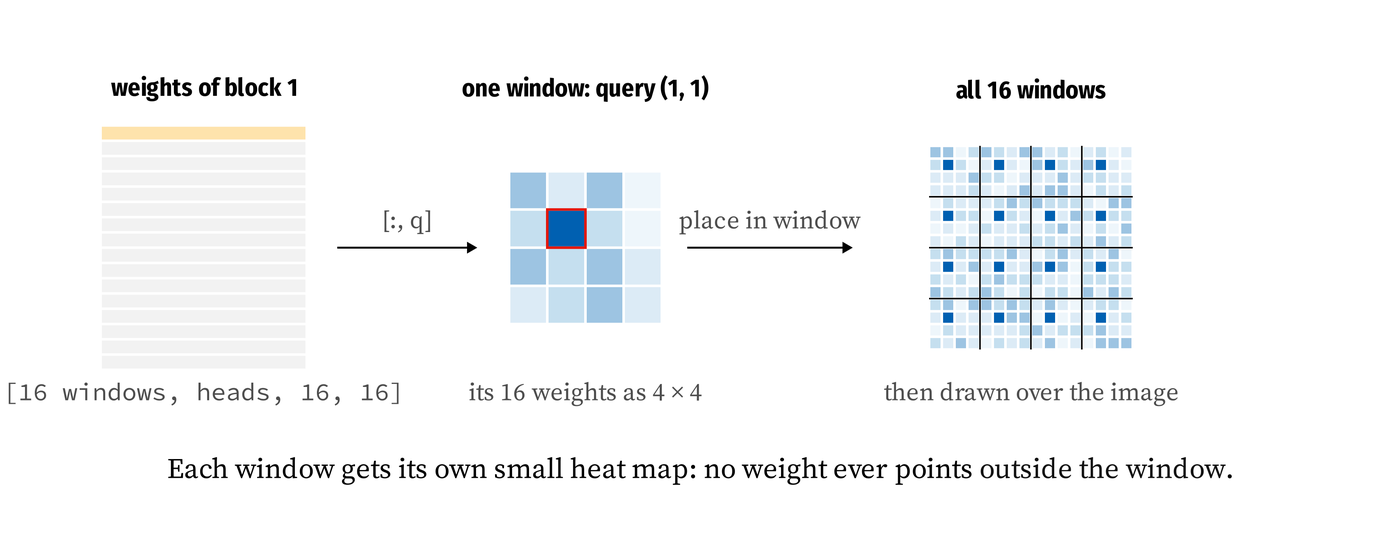

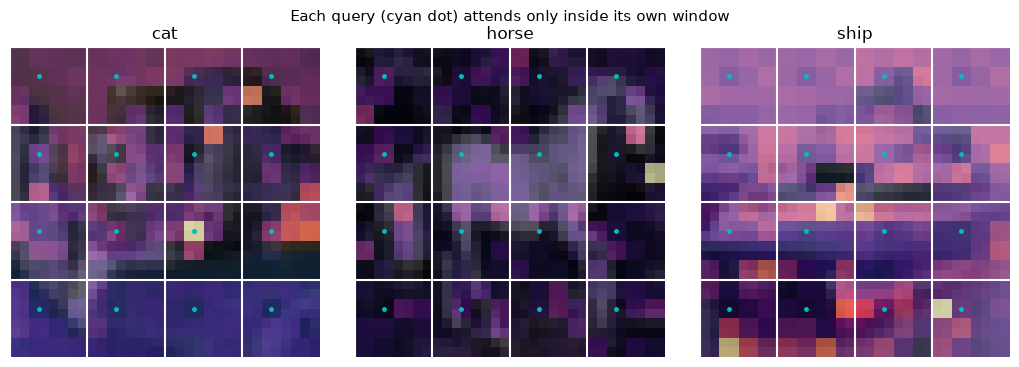

In [28]:
#@title Where one query in each window looks
@torch.no_grad()
def window_attention_canvas(model, image, q_row=1, q_col=1):
    attn = model.stages[0][0].attn
    attn.keep_weights = True
    model.eval(); model(image[None].to(device))
    attn.keep_weights = False
    w = attn.weights.mean(1)                                               # [16 windows, 16, 16]
    q = q_row * WINDOW + q_col
    canvas = torch.zeros(GRID, GRID)
    per_row = GRID // WINDOW
    for k in range(w.shape[0]):
        r0, c0 = (k // per_row) * WINDOW, (k % per_row) * WINDOW
        canvas[r0:r0 + WINDOW, c0:c0 + WINDOW] = w[k, q].reshape(WINDOW, WINDOW).float().cpu()
    return canvas

pick = [next(i for i in range(len(test_set)) if test_set.targets[i] == c) for c in [3, 7, 8]]
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.7))
for ax, i in zip(axes, pick):
    img = test_set[i][0]
    ax.imshow(denorm(img))
    ax.imshow(window_attention_canvas(swin, img), cmap='magma', alpha=.65, extent=(-.5, 31.5, 31.5, -.5), interpolation='nearest')
    draw_grid(ax, win_px, 'white', 1.5)
    for k in range(16):                                                    # mark the query token of every window
        qx = ((k % 4) * WINDOW + 1) * PATCH_SIZE + PATCH_SIZE / 2 - .5
        qy = ((k // 4) * WINDOW + 1) * PATCH_SIZE + PATCH_SIZE / 2 - .5
        ax.plot(qx, qy, 'c.', ms=5)
    ax.set_title(class_names[test_set.targets[i]]); ax.axis('off')
plt.suptitle('Each query (cyan dot) attends only inside its own window', fontsize=11)
plt.tight_layout(); plt.show()

## 17. Conclusions and next experiments

### What this notebook demonstrates

| Comparison | Our numbers (test) | Lesson |
| --- | --- | --- |
| W0 vs W1, accuracy | 79.5% vs 73.2% | On 32 x 32 images, a plain ViT with global attention beat our small Swin |
| W0 vs W1, cost | 0.173 vs 0.082 GMACs; 5,783 vs 7,770 images/s | Windows and merging halve the compute; real speed improves less (1.34x) |
| W1 vs W2 | 73.2% vs 72.5% | The shift costs nothing and helped slightly; one seed is not enough to be sure |
| Influence maps | 16 tokens at every depth vs 16 → 64 → 144 → 256 | Without the shift, stage 1 never mixes information across windows |

### Key terms

| Term | Meaning |
| --- | --- |
| **Window attention (W-MSA)** | Multi-head attention computed separately inside each window of $M \times M$ tokens |
| **Shifted windows (SW-MSA)** | Every second block rolls the grid by half a window so that new windows straddle the old boundaries |
| **Shift mask** | $-\infty$ added to scores between tokens that only became neighbors because of the roll |
| **Relative-position bias** | A learned number per head and relative offset, added to attention scores |
| **Patch merging** | Concatenates 2 x 2 neighbors and projects 4C to 2C: half the side, twice the width |
| **Hierarchy** | A sequence of stages with coarser grids and wider features, as in a CNN |

### Limits of this experiment

- **One seed.** Gaps of a point or less can be noise. Rerun with other values of `SEED` before trusting them.
- **Small images.** On 32 x 32 images a plain ViT is cheap, so Swin's cost advantage is small here. It matters most for large images and for dense tasks such as detection and segmentation, where Swin's multi-scale features are used directly.
- **Short schedule and small model.** Thirty epochs and three stages of two blocks show the mechanism, not the best possible accuracy.
- **No stochastic depth.** Real Swin uses drop-path regularization; we left it out to keep the code short.
- **Unequal compute.** Our Swin does half the ViT's work per image. A fairer accuracy test matches GMACs, for example with `EMBED_DIM = 96` or `DEPTHS = (2, 2, 6)`.

### Experiments to try

1. **Larger windows.** Set `WINDOW = 8` and `SHIFT = 4`. Stage 1 now has 4 windows. What happens to accuracy, GMACs, and speed?
2. **Deeper third stage.** Swin-T puts most of its blocks in stage 3. Try `DEPTHS = (2, 2, 6)`.
3. **Absolute positions.** Add a learned positional embedding after patch embedding and set the bias tables to zero. Which matters more?
4. **No hierarchy.** Remove the merges and keep 16 x 16 tokens throughout (you will need more memory). Is the hierarchy or the windowing doing the work?
5. **Distill a Swin.** Combine this notebook with the DeiT notebook: give Swin a ResNet teacher.

### Where this goes next

The DeiT notebook improved a ViT by changing **how it learns**. This notebook improved it by changing **where attention looks**. The looped-transformer notebook (section 4.4) changes **how many weights the blocks store**: it runs one shared block several times.